# Phase 02 — Data Cleaning, EDA & Market Structure Analysis
### Symbols: NIFTY50 · BANKNIFTY · NIFTYNEXT50

**Reads from Phase 01 output (Google Drive CSVs)**
```
Data/raw/daily/   NIFTY50_daily.csv  BANKNIFTY_daily.csv  NIFTYNEXT50_daily.csv
Data/raw/1min/    NIFTY50_1min.csv   BANKNIFTY_1min.csv   NIFTYNEXT50_1min.csv
```


## [DRIVE] Mount Google Drive


In [1]:
from google.colab import drive
drive.mount('/content/drive')
print('Drive mounted.')

Mounted at /content/drive
Drive mounted.


## [LIBS] Install & Import


In [2]:
!pip install -q statsmodels pandas_market_calendars

import os, warnings, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from scipy import stats
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf
import pandas_market_calendars as mcal

warnings.filterwarnings('ignore')
%matplotlib inline
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 12, 'axes.labelsize': 10, 'figure.facecolor': 'white'})
sns.set_theme(style='darkgrid', palette='muted')

print('Libraries ready.')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 134.9/134.9 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 213.3/213.3 kB 9.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 4.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ibis-framework 9.5.0 requires toolz<1,>=0.11, but you have toolz 1.1.0 which is incompatible.
Libraries ready.


## [CFG] Configuration


In [3]:
GDRIVE_BASE  = '/content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107'
DATA_ROOT    = os.path.join(GDRIVE_BASE, 'Data', 'raw')
DAILY_DIR    = os.path.join(DATA_ROOT, 'daily')
MIN1_DIR     = os.path.join(DATA_ROOT, '1min')
CLEANED_DIR  = os.path.join(GDRIVE_BASE, 'Data', 'cleaned')
IMAGES_DIR   = os.path.join(GDRIVE_BASE, 'Output', 'EDA_Plots')
RESULTS_DIR  = os.path.join(GDRIVE_BASE, 'Data', 'meta_results')

for d in [IMAGES_DIR, RESULTS_DIR, CLEANED_DIR]:
    os.makedirs(d, exist_ok=True)

SYMBOLS     = ['NIFTY50', 'BANKNIFTY', 'NIFTYNEXT50']
DAILY_START = '2010-01-01'
DAILY_END   = '2026-03-31'
FILL_LIMIT  = 2
RANDOM_SEED = 42
TRAIN_FRAC  = 0.70
VAL_FRAC    = 0.15

np.random.seed(RANDOM_SEED)

# Helper: show inline AND save to Drive
def savefig(name: str):
    path = os.path.join(IMAGES_DIR, name)
    plt.savefig(path, dpi=120, bbox_inches='tight')
    plt.show()
    plt.close()
    print(f'  Saved: {path}')

print('Config loaded.')
print(f'  Symbols  : {SYMBOLS}')
print(f'  Images   : {IMAGES_DIR}')


Config loaded.
  Symbols  : ['NIFTY50', 'BANKNIFTY', 'NIFTYNEXT50']
  Images   : /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots


## 2.1 — Load Phase 01 CSVs


In [4]:
daily = {}
min1  = {}

REQUIRED_OHLCV = ['open', 'high', 'low', 'close', 'volume']


def clean_ohlcv_index(df, index_name):
    df = df.copy()
    df = df[~df.index.duplicated(keep='last')].sort_index()
    df.index.name = index_name
    for col in REQUIRED_OHLCV:
        df[col] = pd.to_numeric(df[col], errors='coerce')
    df = df.dropna(subset=['open', 'high', 'low', 'close'])
    valid_prices = (df[['open', 'high', 'low', 'close']] > 0).all(axis=1)
    df = df.loc[valid_prices]
    df['volume'] = df['volume'].fillna(0).clip(lower=0)
    return df.astype(float)

print('-- Loading daily CSVs --')
for sym in SYMBOLS:
    path = os.path.join(DAILY_DIR, f'{sym}_daily.csv')
    if not os.path.exists(path):
        print(f'  MISSING: {path}'); continue
    raw = pd.read_csv(path, index_col='date', parse_dates=True)
    raw.index = pd.to_datetime(raw.index, errors='coerce').tz_localize(None).normalize()
    raw = raw.loc[raw.index.notna(), REQUIRED_OHLCV]
    df = clean_ohlcv_index(raw, 'date')
    daily[sym] = df
    print(f'  {sym}: {len(df):,} rows | {df.index[0].date()} to {df.index[-1].date()}')
    display(df.head(1))
    print()

print()
print('-- Loading 1-min CSVs --')
for sym in SYMBOLS:
    path = os.path.join(MIN1_DIR, f'{sym}_1min.csv')
    if not os.path.exists(path):
        print(f'  MISSING: {path}'); continue
    raw = pd.read_csv(path, index_col='datetime', parse_dates=True)
    raw.index = pd.to_datetime(raw.index, errors='coerce').tz_localize(None)
    raw = raw.loc[raw.index.notna(), REQUIRED_OHLCV]
    df = clean_ohlcv_index(raw, 'datetime')
    min1[sym] = df
    print(f'  {sym}: {len(df):,} bars | {df.index[0]} to {df.index[-1]}')
    display(df.head(1))
    print()


-- Loading daily CSVs --
  NIFTY50: 4,546 rows | 2007-09-17 to 2026-03-30


,open,high,low,close,volume
date,,,,,
2007-09-17,4518.450195,4549.049805,4482.850098,4494.649902,0.0



  BANKNIFTY: 4,561 rows | 2007-09-17 to 2026-03-30


,open,high,low,close,volume
date,,,,,
2007-09-17,6897.919911,6977.119187,6842.92055,6897.02002,0.0



  NIFTYNEXT50: 4,252 rows | 2007-09-17 to 2026-03-30


...

,open,high,low,close,volume
datetime,,,,,
2024-03-11 09:15:00,22517.5,22526.6,22460.95,22490.0,0.0



  BANKNIFTY: 186,593 bars | 2024-03-11 09:15:00 to 2026-03-30 15:29:00


,open,high,low,close,volume
datetime,,,,,
2024-03-11 09:15:00,47792.2,47853.8,47666.55,47728.7,0.0



  NIFTYNEXT50: 186,594 bars | 2024-03-11 09:15:00 to 2026-03-30 15:29:00


,open,high,low,close,volume
datetime,,,,,
2024-03-11 09:15:00,60467.45,60468.1,60253.2,60337.2,0.0


## 2.2 — OHLC Consistency Enforcement
Ensures `H >= max(O,C)` and `L <= min(O,C)` for every bar.


In [5]:
def enforce_ohlc(df):
    df = df.copy()
    df['high'] = df[['open','high','close']].max(axis=1)
    df['low']  = df[['open','low','close']].min(axis=1)
    return df

for sym in list(daily.keys()):
    before = daily[sym].copy()
    daily[sym] = enforce_ohlc(daily[sym])
    n = ((daily[sym]['high'] != before['high']) | (daily[sym]['low'] != before['low'])).sum()
    print(f'  {sym} daily : {n} bars corrected')

for sym in list(min1.keys()):
    before = min1[sym].copy()
    min1[sym] = enforce_ohlc(min1[sym])
    n = ((min1[sym]['high'] != before['high']) | (min1[sym]['low'] != before['low'])).sum()
    print(f'  {sym} 1min  : {n} bars corrected')


  NIFTY50 daily : 0 bars corrected
  BANKNIFTY daily : 0 bars corrected
  NIFTYNEXT50 daily : 0 bars corrected
  NIFTY50 1min  : 0 bars corrected
  BANKNIFTY 1min  : 0 bars corrected
  NIFTYNEXT50 1min  : 0 bars corrected


## 2.3 — Gap Detection & Forward-Fill (Daily)
Reindexes to NSE trading calendar; forward-fills gaps <= FILL_LIMIT; drops the rest.


In [6]:
nse_cal  = mcal.get_calendar('NSE')
schedule = nse_cal.schedule(start_date=DAILY_START, end_date=DAILY_END)
nse_days = mcal.date_range(schedule, frequency='1D').normalize().tz_localize(None)

def fill_daily_gaps(df, fill_limit=FILL_LIMIT):
    cal = nse_days[(nse_days >= df.index.min()) & (nse_days <= df.index.max())]
    df  = df.reindex(cal)
    missing_before = df['close'].isna()
    run_ids   = (missing_before != missing_before.shift()).cumsum()
    run_lens  = missing_before.groupby(run_ids).transform('sum')
    fillable  = missing_before & (run_lens <= fill_limit)
    df.loc[fillable] = df.ffill(limit=fill_limit).loc[fillable]
    bars_ffilled = int(fillable.sum())
    bars_dropped = int(df['close'].isna().sum())
    df.dropna(subset=['open','high','low','close'], inplace=True)
    return df, bars_ffilled, bars_dropped

gap_report = []
for sym in list(daily.keys()):
    before = len(daily[sym])
    daily[sym], bars_ffilled, bars_dropped = fill_daily_gaps(daily[sym])
    after  = len(daily[sym])
    gap_report.append({
        'symbol': sym,
        'rows_before': before,
        'rows_after': after,
        'calendar_bars_ffilled': bars_ffilled,
        'calendar_bars_dropped': bars_dropped,
        'row_count_delta': after - before,
    })
    print(f'  {sym}: {before} -> {after} rows | filled={bars_ffilled} | dropped={bars_dropped}')

pd.DataFrame(gap_report).to_csv(os.path.join(RESULTS_DIR, 'gap_report_daily.csv'), index=False)
print('Gap report saved.')


  NIFTY50: 4546 -> 4010 rows | filled=28 | dropped=0
  BANKNIFTY: 4561 -> 4010 rows | filled=12 | dropped=0
  NIFTYNEXT50: 4252 -> 3742 rows | filled=53 | dropped=268
Gap report saved.


## 2.4 — Outlier Winsorisation
Log-return winsorisation at [0.5%, 99.5%]; volume outliers tagged.


In [7]:
def winsorise_close(df, lo=0.005, hi=0.995):
    df = df.copy()
    log_ret = np.log(df['close'] / df['close'].shift(1)).dropna()
    log_ret_w = log_ret.clip(log_ret.quantile(lo), log_ret.quantile(hi))
    clean = [df['close'].iloc[0]]
    for i in range(1, len(df)):
        r = log_ret_w.get(df.index[i], 0.0)
        clean.append(clean[-1] * np.exp(r))
    df['close'] = clean
    df['high']  = df[['open','high','close']].max(axis=1)
    df['low']   = df[['open','low','close']].min(axis=1)
    return df

def tag_volume_outliers(df, p_lo=0.01, p_hi=0.99):
    df = df.copy()
    v = df['volume'].replace(0, np.nan).dropna()
    df['volume_outlier'] = (df['volume'] < v.quantile(p_lo)) | (df['volume'] > v.quantile(p_hi))
    return df

for sym in list(daily.keys()):
    daily[sym] = winsorise_close(daily[sym])
    daily[sym] = tag_volume_outliers(daily[sym])
    print(f'  {sym}: winsorised | vol outliers = {daily[sym]["volume_outlier"].sum()}')


  NIFTY50: winsorised | vol outliers = 853
  BANKNIFTY: winsorised | vol outliers = 1962
  NIFTYNEXT50: winsorised | vol outliers = 2122


## 2.5 — Resample 1-Min → 5/15/30/60-Min
Session-filtered to NSE hours 09:15–15:30.


In [8]:
RESAMPLE_FREQS = {'5min':'5min', '15min':'15min', '30min':'30min', '60min':'60min'}
OHLCV_AGG = {'open':'first','high':'max','low':'min','close':'last','volume':'sum'}
SESSION_START, SESSION_END = '09:15', '15:30'

resampled = {}   # resampled[sym][tf] -> DataFrame

for sym in list(min1.keys()):
    resampled[sym] = {}
    min1[sym] = min1[sym].between_time(SESSION_START, SESSION_END).copy()
    df = min1[sym]
    for tf, freq in RESAMPLE_FREQS.items():
        rs = df.resample(freq, origin='start').agg(OHLCV_AGG).dropna(subset=['open'])
        rs = rs.between_time(SESSION_START, SESSION_END)
        resampled[sym][tf] = enforce_ohlc(rs)
        print(f'  {sym} {tf}: {len(rs):,} bars | {rs.index[0]} to {rs.index[-1]}')


  NIFTY50 5min: 37,308 bars | 2024-03-11 09:15:00 to 2026-03-30 15:25:00
  NIFTY50 15min: 12,436 bars | 2024-03-11 09:15:00 to 2026-03-30 15:15:00
  NIFTY50 30min: 6,468 bars | 2024-03-11 09:15:00 to 2026-03-30 15:15:00
  NIFTY50 60min: 3,484 bars | 2024-03-11 09:15:00 to 2026-03-30 15:15:00
  BANKNIFTY 5min: 37,308 bars | 2024-03-11 09:15:00 to 2026-03-30 15:25:00
  BANKNIFTY 15min: 12,436 bars | 2024-03-11 09:15:00 to 2026-03-30 15:15:00
  BANKNIFTY 30min: 6,468 bars | 2024-03-11 09:15:00 to 2026-03-30 15:15:00
  BANKNIFTY 60min: 3,484 bars | 2024-03-11 09:15:00 to 2026-03-30 15:15:00
  NIFTYNEXT50 5min: 37,308 bars | 2024-03-11 09:15:00 to 2026-03-30 15:25:00
  NIFTYNEXT50 15min: 12,436 bars | 2024-03-11 09:15:00 to 2026-03-30 15:15:00
  NIFTYNEXT50 30min: 6,468 bars | 2024-03-11 09:15:00 to 2026-03-30 15:15:00
  NIFTYNEXT50 60min: 3,484 bars | 2024-03-11 09:15:00 to 2026-03-30 15:15:00


## 2.6 — Stationarity Tests & Stylised Facts
ADF + KPSS on daily log returns; Ljung-Box Q(10) for autocorrelation.


In [9]:
def stationarity_report(df, sym, tf):
    if df.empty or len(df) < 50: return {}
    lr = np.log(df['close'] / df['close'].shift(1)).dropna()
    adf_stat, adf_p = adfuller(lr, autolag='AIC')[:2]
    try:
        kpss_stat, kpss_p = kpss(lr, regression='c', nlags='auto')[:2]
    except:
        kpss_stat, kpss_p = np.nan, np.nan
    lb_p = acorr_ljungbox(lr, lags=[10], return_df=True)['lb_pvalue'].iloc[0]
    return {
        'symbol': sym, 'timeframe': tf, 'n_obs': len(lr),
        'adf_stat': round(adf_stat,4), 'adf_p': round(adf_p,4),
        'adf_stationary': adf_p < 0.05,
        'kpss_stat': round(kpss_stat,4), 'kpss_p': round(float(kpss_p),4),
        'kpss_stationary': kpss_p > 0.05,
        'excess_kurtosis': round(float(stats.kurtosis(lr)),4),
        'skewness': round(float(stats.skew(lr)),4),
        'lb_q10_p': round(float(lb_p),4),
        'ann_vol': round(float(lr.std() * np.sqrt(252)),4),
    }

stat_records = [stationarity_report(daily[s], s, '1day') for s in SYMBOLS if s in daily]
df_stat = pd.DataFrame([r for r in stat_records if r])
df_stat.to_csv(os.path.join(RESULTS_DIR, 'stationarity_report.csv'), index=False)
print(df_stat[['symbol','n_obs','adf_stationary','kpss_stationary',
               'excess_kurtosis','skewness','ann_vol']].to_string(index=False))


     symbol  n_obs  adf_stationary  kpss_stationary  excess_kurtosis  skewness  ann_vol
    NIFTY50   4009            True             True           1.3215   -0.1550   0.1527
  BANKNIFTY   4009            True             True           1.5527   -0.1280   0.2123
NIFTYNEXT50   3741            True             True           1.3952   -0.4249   0.1765


## 2.7 — Basic EDA: Log Price · Returns · Rolling Vol · Volume


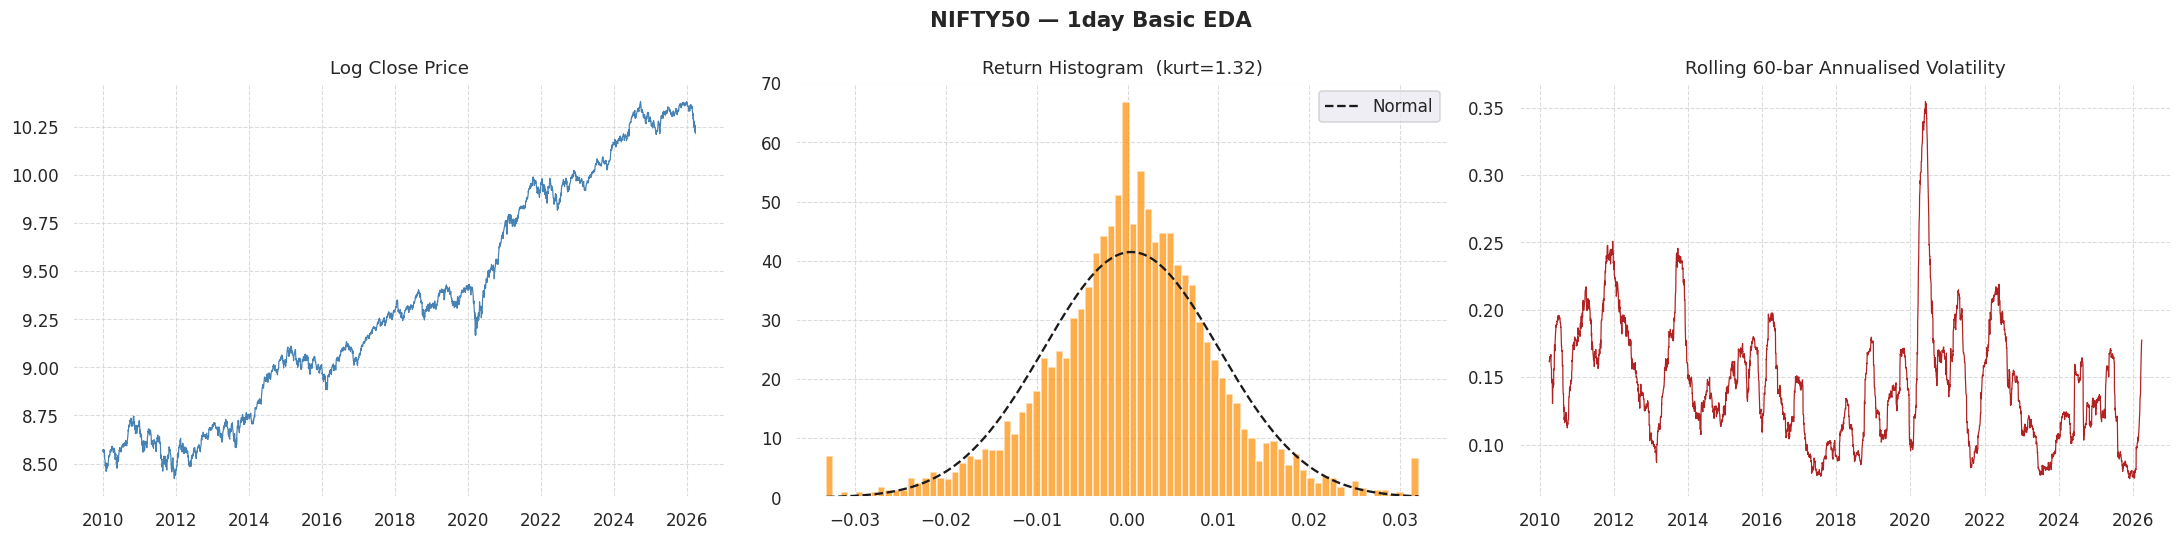

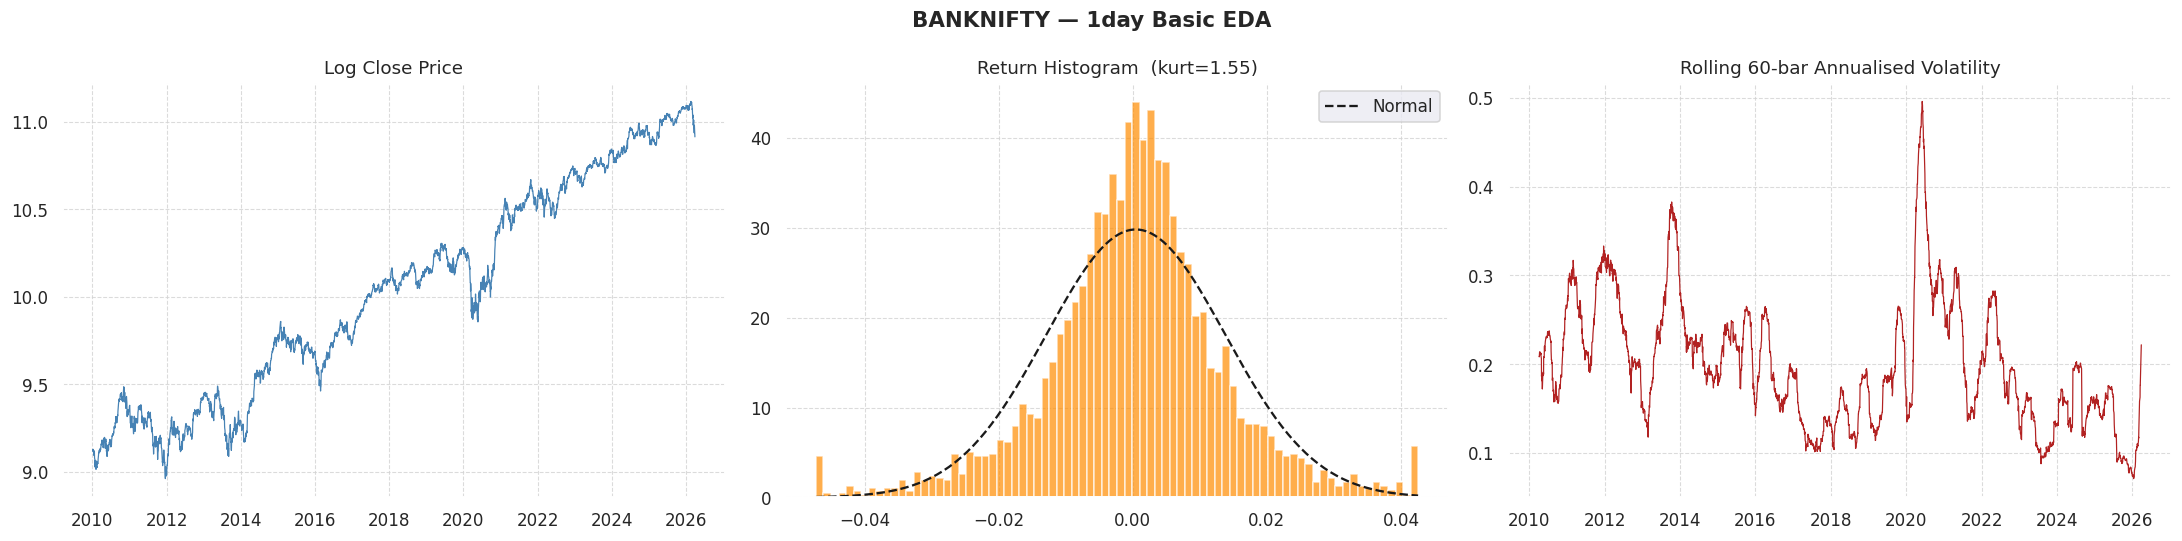

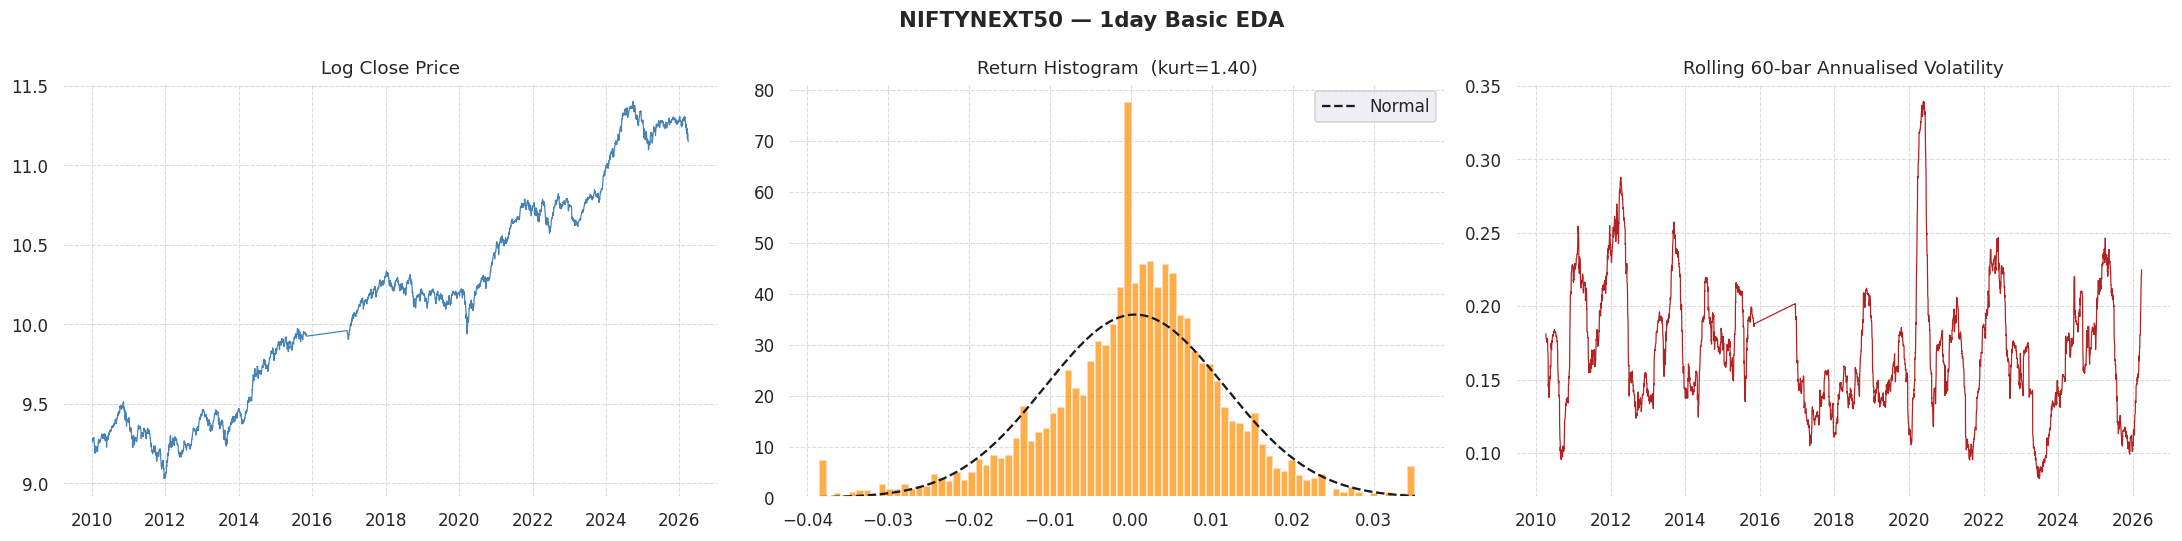

In [21]:
def plot_basic_eda(sym, df, tf='1day'):
    if df.empty or len(df) < 50:
        return
    lr = np.log(df['close'] / df['close'].shift(1)).dropna()
    fig, axes = plt.subplots(1, 3, figsize=(20, 5), facecolor='white')
    fig.suptitle(f'{sym} — {tf} Basic EDA', fontsize=14, fontweight='bold')

    for ax in axes:
        ax.set_facecolor('white')
        ax.grid(True, axis='both', color='lightgray', linestyle='--', linewidth=0.7, alpha=0.8, zorder=0)
        ax.set_axisbelow(True)

    axes[0].plot(df.index, np.log(df['close']), color='steelblue', lw=0.8)
    axes[0].set_title('Log Close Price')
    axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

    axes[1].hist(lr, bins=80, color='darkorange', alpha=0.7, density=True)
    x = np.linspace(lr.min(), lr.max(), 200)
    axes[1].plot(x, stats.norm.pdf(x, lr.mean(), lr.std()), 'k--', lw=1.5, label='Normal')
    axes[1].set_title(f'Return Histogram  (kurt={stats.kurtosis(lr):.2f})')
    axes[1].legend()

    roll_vol = lr.rolling(60).std() * np.sqrt(252)
    axes[2].plot(roll_vol.index, roll_vol, color='firebrick', lw=0.8)
    axes[2].set_title('Rolling 60-bar Annualised Volatility')
    axes[2].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

    fig.patch.set_facecolor('white')
    plt.tight_layout()
    # Optional save
    # fig.savefig(f'Plot01_{sym}_{tf}_basic_eda.png')
    plt.show()
    plt.close(fig)


# Run for all symbols
for sym in SYMBOLS:
    if sym in daily:
        plot_basic_eda(sym, daily[sym], '1day')

In [ ]:
def plot_basic_eda(sym, df, tf='1day'):
    if df.empty or len(df) < 50:
        return

    lr = np.log(df['close'] / df['close'].shift(1)).dropna()
    fig, axes = plt.subplots(1, 3, figsize=(20, 5), facecolor='white')
    fig.suptitle(f'{sym} — {tf} Basic EDA', fontsize=14, fontweight='bold')

    for ax in axes:
        ax.set_facecolor('white')
    axes[0].plot(df.index, np.log(df['close']), color='steelblue', lw=0.8)
    axes[0].set_title('Log Close Price')
    axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    axes[0].grid(False)

    axes[1].hist(lr, bins=80, color='darkorange', alpha=0.7, density=True)
    x = np.linspace(lr.min(), lr.max(), 200)
    axes[1].plot(x, stats.norm.pdf(x, lr.mean(), lr.std()), 'k--', lw=1.5, label='Normal')
    axes[1].set_title(f'Return Histogram  (kurt={stats.kurtosis(lr):.2f})')
    axes[1].legend()
    axes[1].grid(False)

    roll_vol = lr.rolling(60).std() * np.sqrt(252)
    axes[2].plot(roll_vol.index, roll_vol, color='firebrick', lw=0.8)
    axes[2].set_title('Rolling 60-bar Annualised Volatility')
    axes[2].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    axes[2].grid(False)

    fig.patch.set_facecolor('white')
    plt.tight_layout()

    savefig(f'Plot01_{sym}_{tf}_basic_eda.png', facecolor='white', bbox_inches='tight', dpi=300)
    plt.show()

# Run for all symbols
for sym in SYMBOLS:
    if sym in daily:
        plot_basic_eda(sym, daily[sym], '1day')

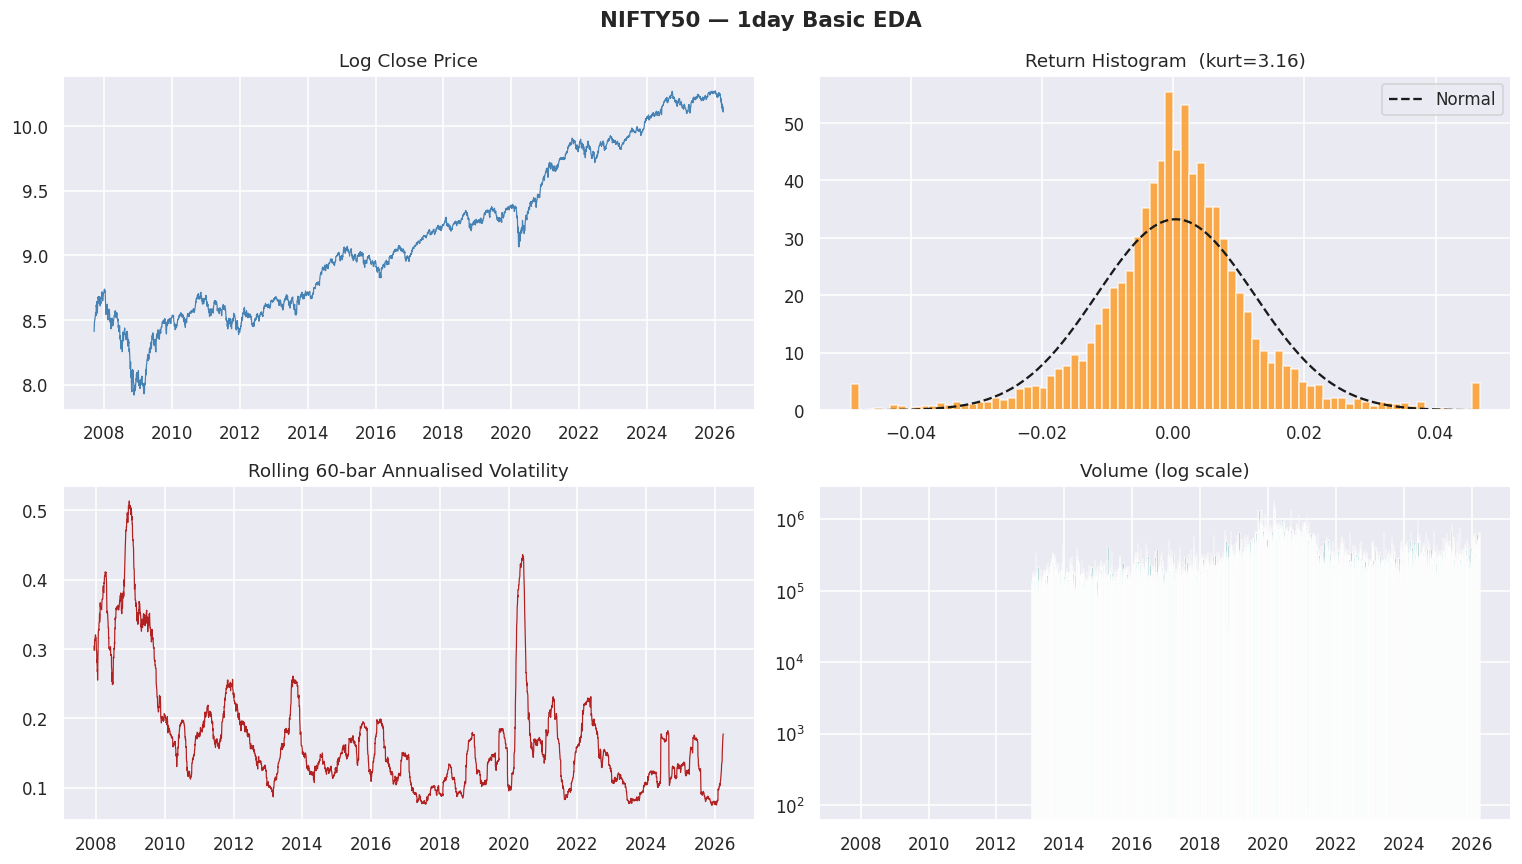

  Saved: /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot01_NIFTY50_1day_basic_eda.png


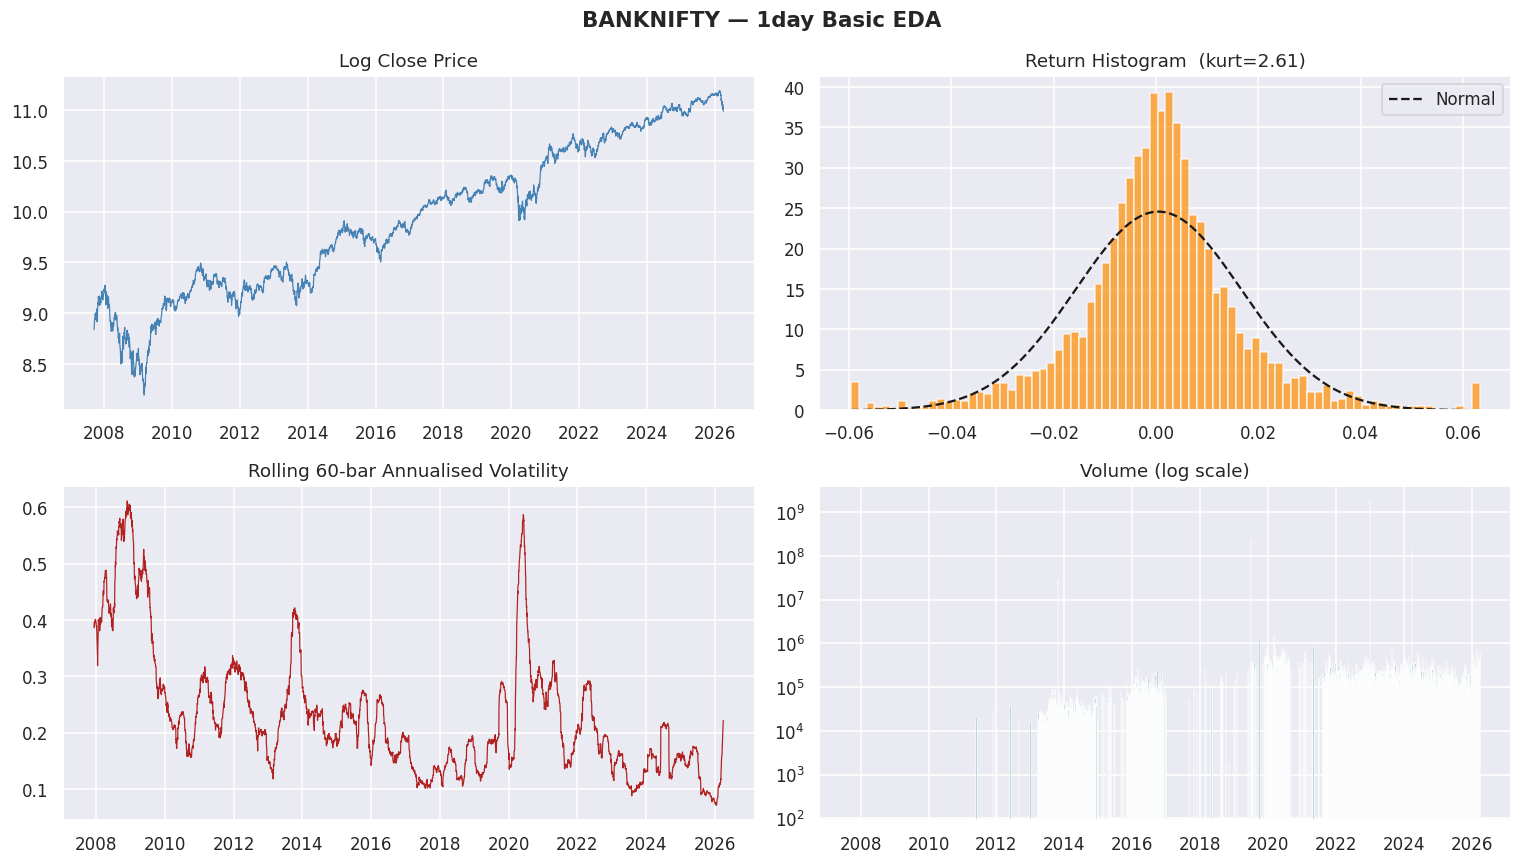

  Saved: /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot01_BANKNIFTY_1day_basic_eda.png


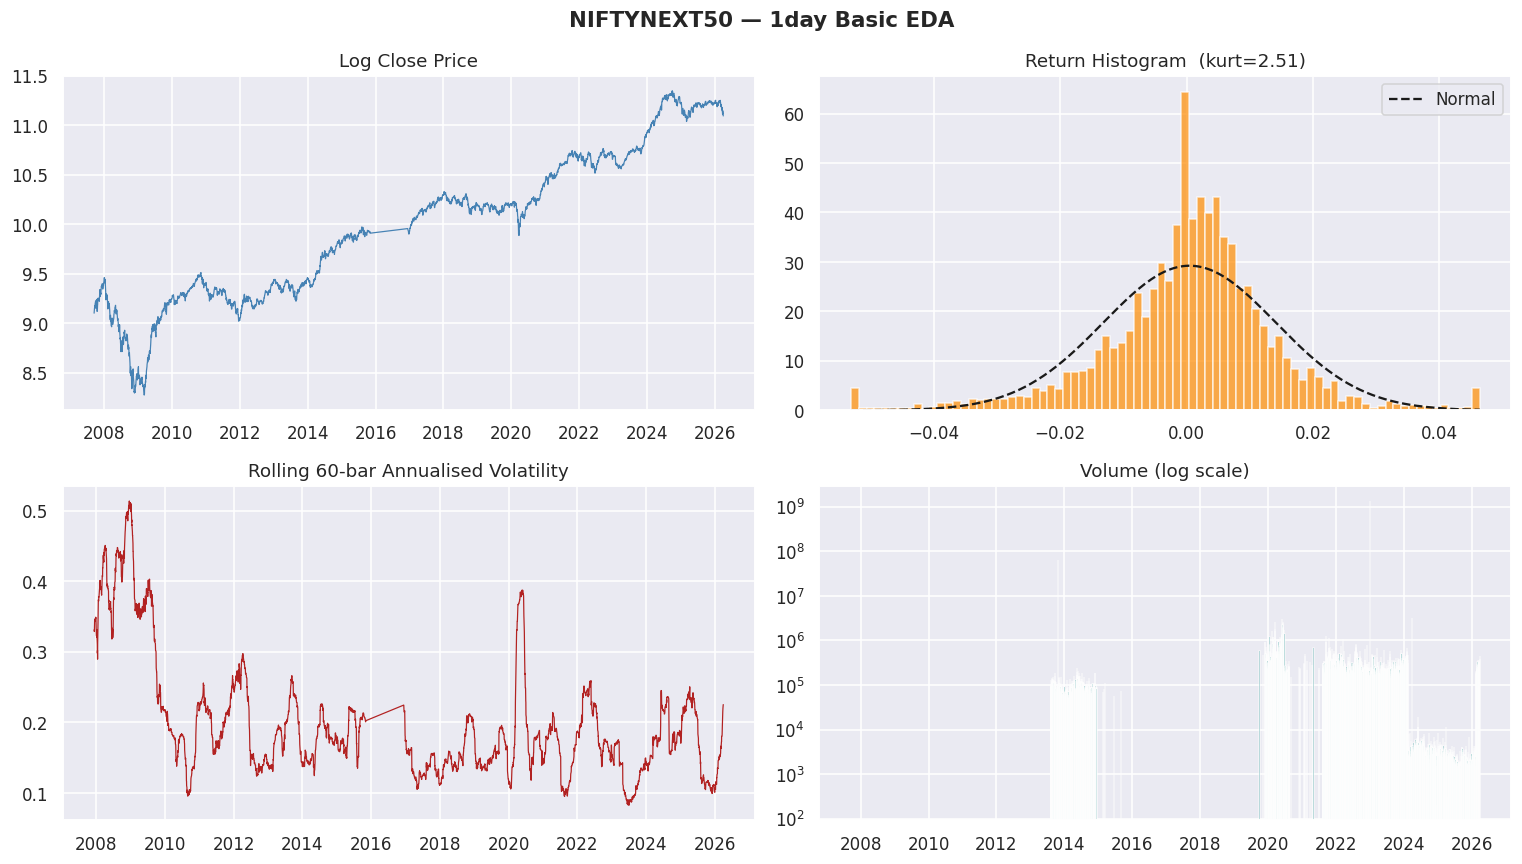

  Saved: /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot01_NIFTYNEXT50_1day_basic_eda.png


In [ ]:
def plot_basic_eda(sym, df, tf='1day'):
    if df.empty or len(df) < 50: return
    lr = np.log(df['close'] / df['close'].shift(1)).dropna()
    fig, axes = plt.subplots(2, 2, figsize=(14, 8))
    fig.suptitle(f'{sym} — {tf} Basic EDA', fontsize=14, fontweight='bold')

    axes[0,0].plot(df.index, np.log(df['close']), color='steelblue', lw=0.8)
    axes[0,0].set_title('Log Close Price')
    axes[0,0].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

    axes[0,1].hist(lr, bins=80, color='darkorange', alpha=0.7, density=True)
    x = np.linspace(lr.min(), lr.max(), 200)
    axes[0,1].plot(x, stats.norm.pdf(x, lr.mean(), lr.std()), 'k--', lw=1.5, label='Normal')
    axes[0,1].set_title(f'Return Histogram  (kurt={stats.kurtosis(lr):.2f})')
    axes[0,1].legend()

    roll_vol = lr.rolling(60).std() * np.sqrt(252)
    axes[1,0].plot(roll_vol.index, roll_vol, color='firebrick', lw=0.8)
    axes[1,0].set_title('Rolling 60-bar Annualised Volatility')
    axes[1,0].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

    axes[1,1].bar(df.index, df['volume'], color='teal', alpha=0.5, width=1)
    axes[1,1].set_yscale('log')
    axes[1,1].set_title('Volume (log scale)')
    axes[1,1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

    plt.tight_layout()
    savefig(f'Plot01_{sym}_{tf}_basic_eda.png')

for sym in SYMBOLS:
    if sym in daily:
        plot_basic_eda(sym, daily[sym], '1day')

## 2.8 — Volatility Clustering
**Question:** Do high-volatility periods cluster statistically?

Computes ACF of 20-day rolling volatility and squared returns.
Slow decay in ACF confirms regime persistence — justifies LSTM / regime models.


  NIFTY50: vol ACF drops below 0.10 at lag >50 days
  BANKNIFTY: vol ACF drops below 0.10 at lag >50 days
  NIFTYNEXT50: vol ACF drops below 0.10 at lag >50 days


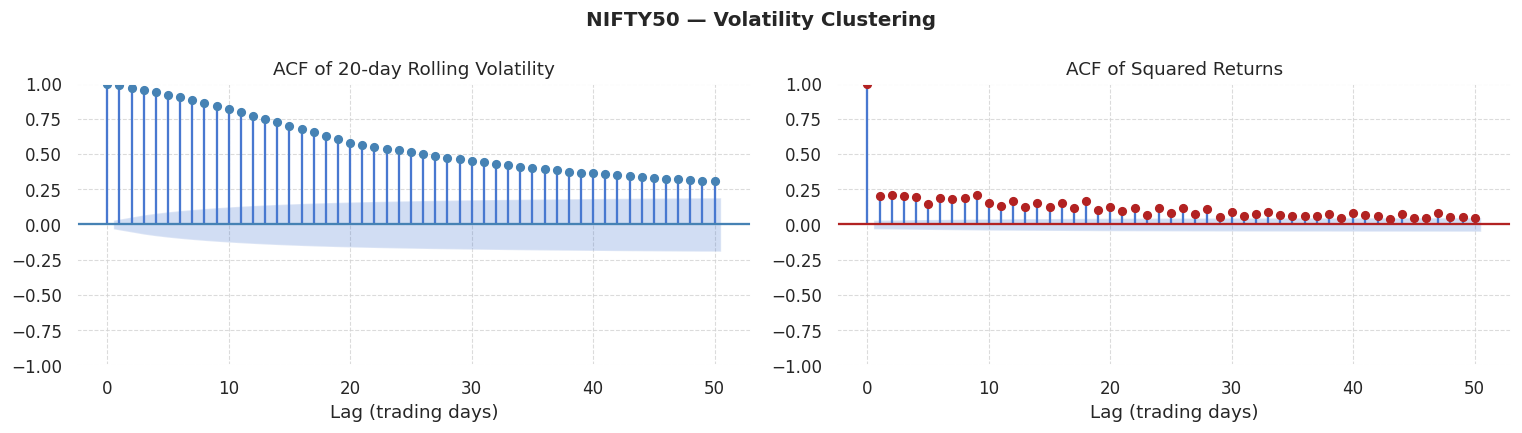

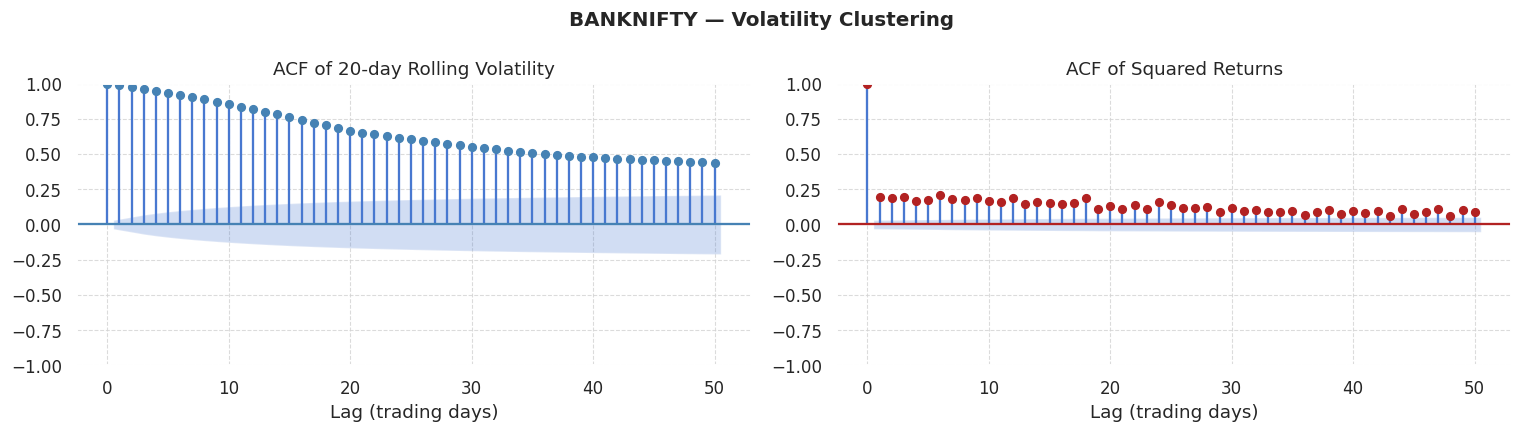

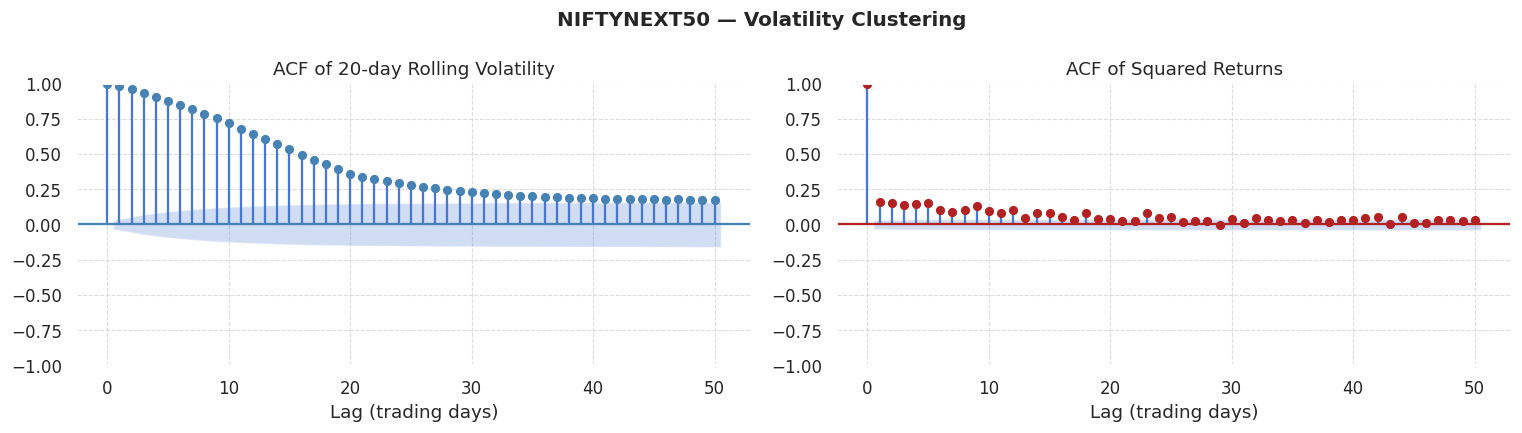

In [23]:
for sym in SYMBOLS:
    if sym not in daily: continue
    lr   = np.log(daily[sym]['close'] / daily[sym]['close'].shift(1)).dropna()
    vol  = lr.rolling(20).std().dropna()
    vol2 = lr.pow(2).dropna()   # squared returns

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    fig.suptitle(f'{sym} — Volatility Clustering', fontsize=13, fontweight='bold')

    for ax in axes:
        ax.set_facecolor('white')
        ax.grid(True, axis='both', color='lightgray', linestyle='--', linewidth=0.7, alpha=0.8, zorder=0)
        ax.set_axisbelow(True)

    plot_acf(vol, lags=50, ax=axes[0], color='steelblue', alpha=0.05)
    axes[0].set_title('ACF of 20-day Rolling Volatility')
    axes[0].set_xlabel('Lag (trading days)')

    plot_acf(vol2, lags=50, ax=axes[1], color='firebrick', alpha=0.05)
    axes[1].set_title('ACF of Squared Returns')
    axes[1].set_xlabel('Lag (trading days)')

    fig.patch.set_facecolor('white')
    plt.tight_layout()
    # savefig(f'Plot02_{sym}_volatility_clustering.png')

    # Quantify: first lag where ACF drops below 0.1
    from statsmodels.tsa.stattools import acf as acf_fn
    acf_vals = acf_fn(vol, nlags=50, fft=True)
    below = np.where(acf_vals < 0.1)[0]
    persistence = below[0] if len(below) else '>50'
    print(f'  {sym}: vol ACF drops below 0.10 at lag {persistence} days')


## 2.9 — Heavy-Tail Verification (Q-Q Plot)
**Question:** How heavy are tails vs Normal?

Deviations at tails confirm fat-tail risk. Extreme events are underestimated
by normal models — important for risk regimes and crisis detection.


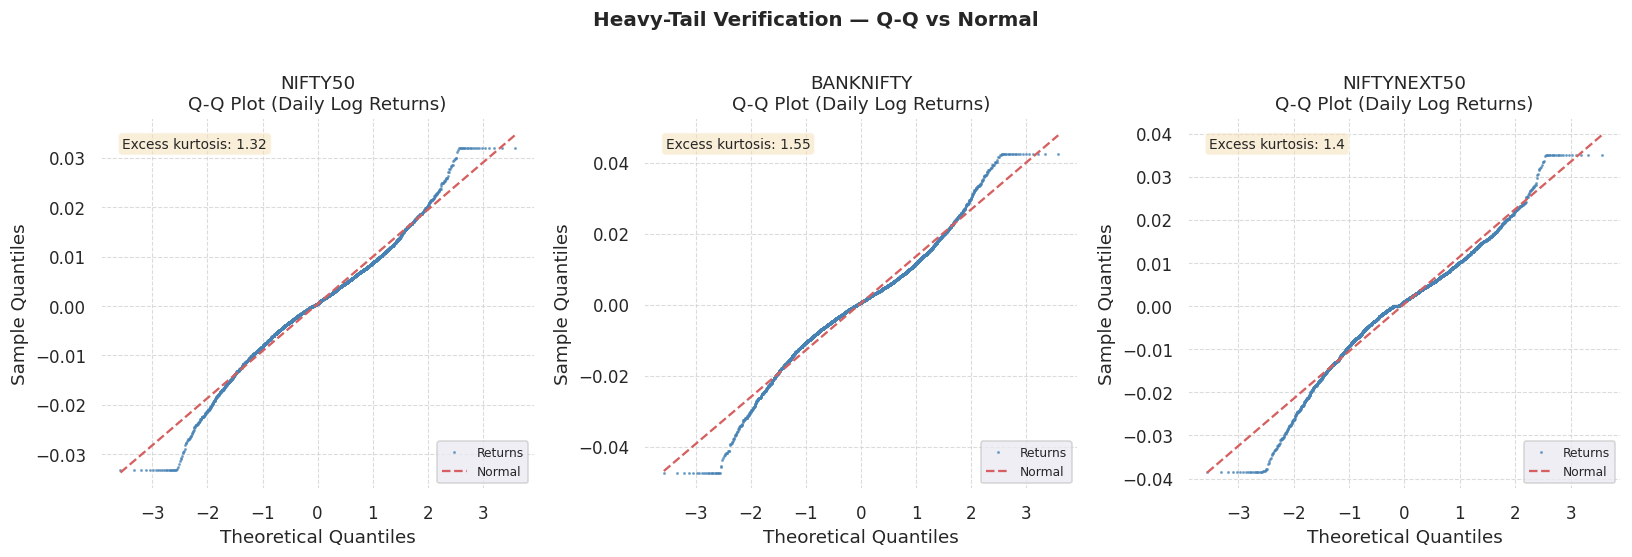

  Saved: /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot03_all_symbols_qq_plot.png


In [24]:
fig, axes = plt.subplots(1, len(SYMBOLS), figsize=(5*len(SYMBOLS), 5))
if len(SYMBOLS) == 1: axes = [axes]

for ax in axes:
    ax.set_facecolor('white')
    ax.grid(True, axis='both', color='lightgray', linestyle='--', linewidth=0.7, alpha=0.8, zorder=0)
    ax.set_axisbelow(True)

for ax, sym in zip(axes, SYMBOLS):
    if sym not in daily: continue
    lr = np.log(daily[sym]['close'] / daily[sym]['close'].shift(1)).dropna()
    (osm, osr), (slope, intercept, r) = stats.probplot(lr, dist='norm')
    ax.plot(osm, osr, '.', markersize=2, color='steelblue', alpha=0.6, label='Returns')
    ax.plot(osm, slope*np.array(osm)+intercept, 'r--', lw=1.5, label='Normal')
    ax.set_title(f'{sym}\nQ-Q Plot (Daily Log Returns)')
    ax.set_xlabel('Theoretical Quantiles')
    ax.set_ylabel('Sample Quantiles')
    ax.legend(fontsize=8)
    tail_kurt = round(float(stats.kurtosis(lr)), 2)
    ax.text(0.05, 0.95, f'Excess kurtosis: {tail_kurt}', transform=ax.transAxes, va='top', fontsize=9, bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.suptitle('Heavy-Tail Verification — Q-Q vs Normal', fontsize=13, fontweight='bold', y=1.01)
fig.patch.set_facecolor('white')
plt.tight_layout()
savefig('Plot03_all_symbols_qq_plot.png')


## 2.10 — Regime Segmentation (Volatility Quantiles)
**Question:** Can we visually segment market regimes?

20-day rolling vol split into Low/Medium/High terciles.
Colour blocks confirm regimes are persistent, not random.


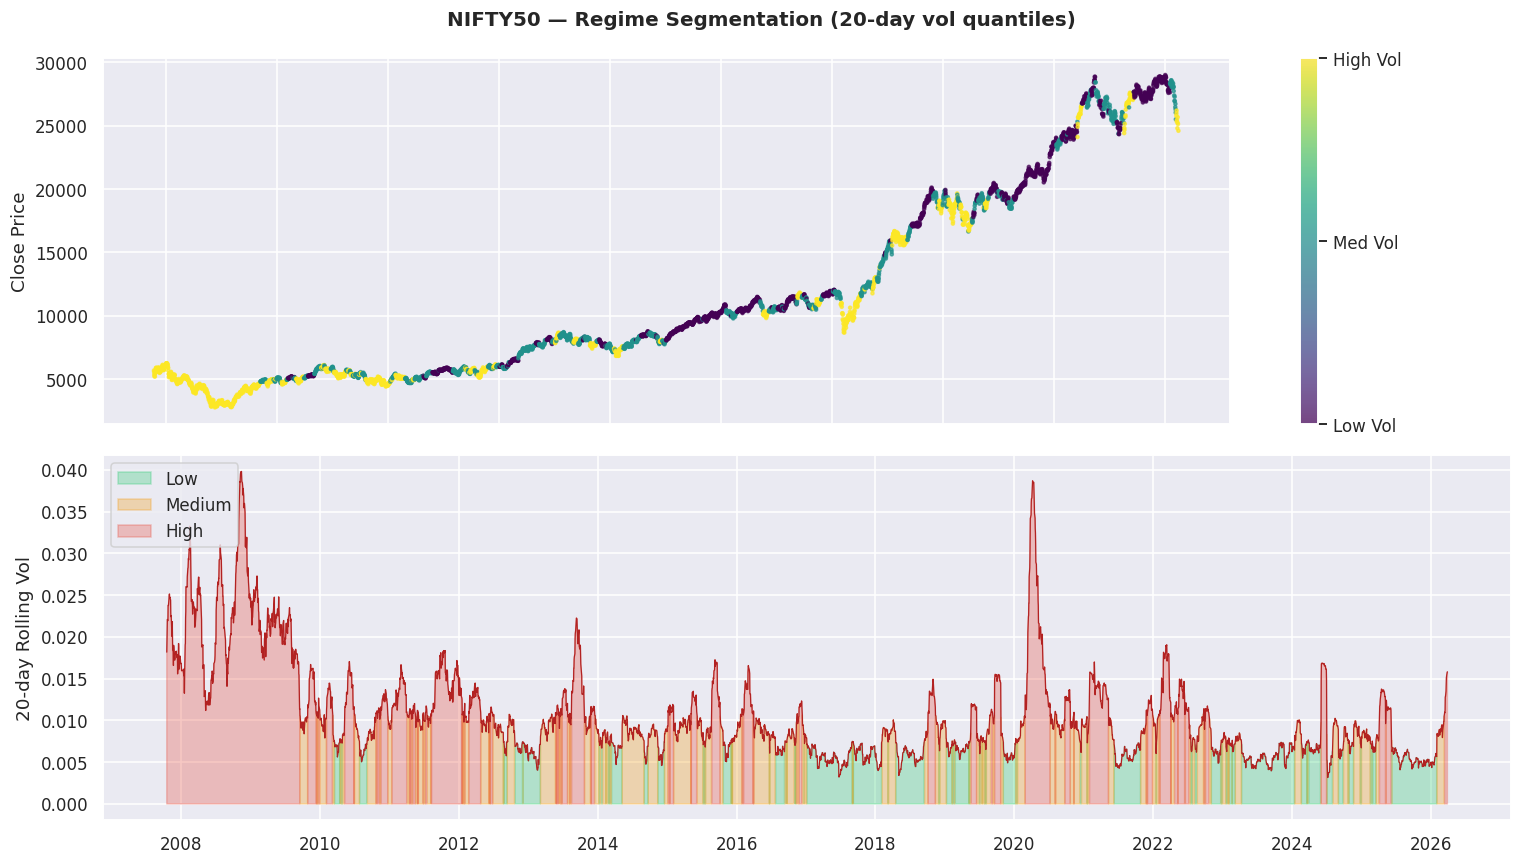

  Saved: /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot04_NIFTY50_regime_segmentation.png
  NIFTY50 | Low    regime: 1517 days (33.3%)
  NIFTY50 | Medium regime: 1517 days (33.3%)
  NIFTY50 | High   regime: 1517 days (33.3%)


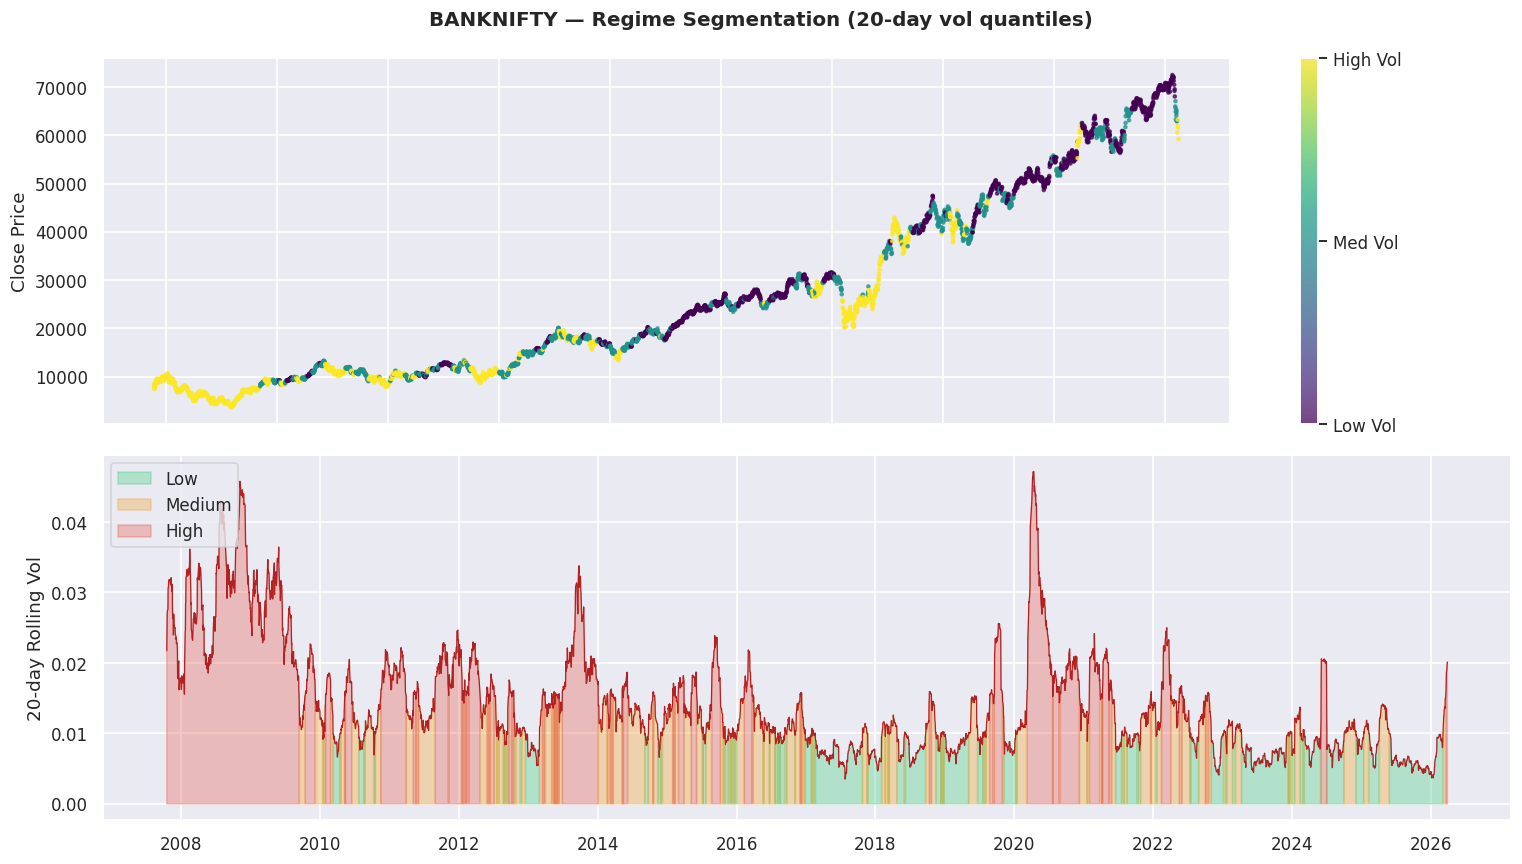

  Saved: /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot04_BANKNIFTY_regime_segmentation.png
  BANKNIFTY | Low    regime: 1517 days (33.3%)
  BANKNIFTY | Medium regime: 1517 days (33.3%)
  BANKNIFTY | High   regime: 1517 days (33.3%)


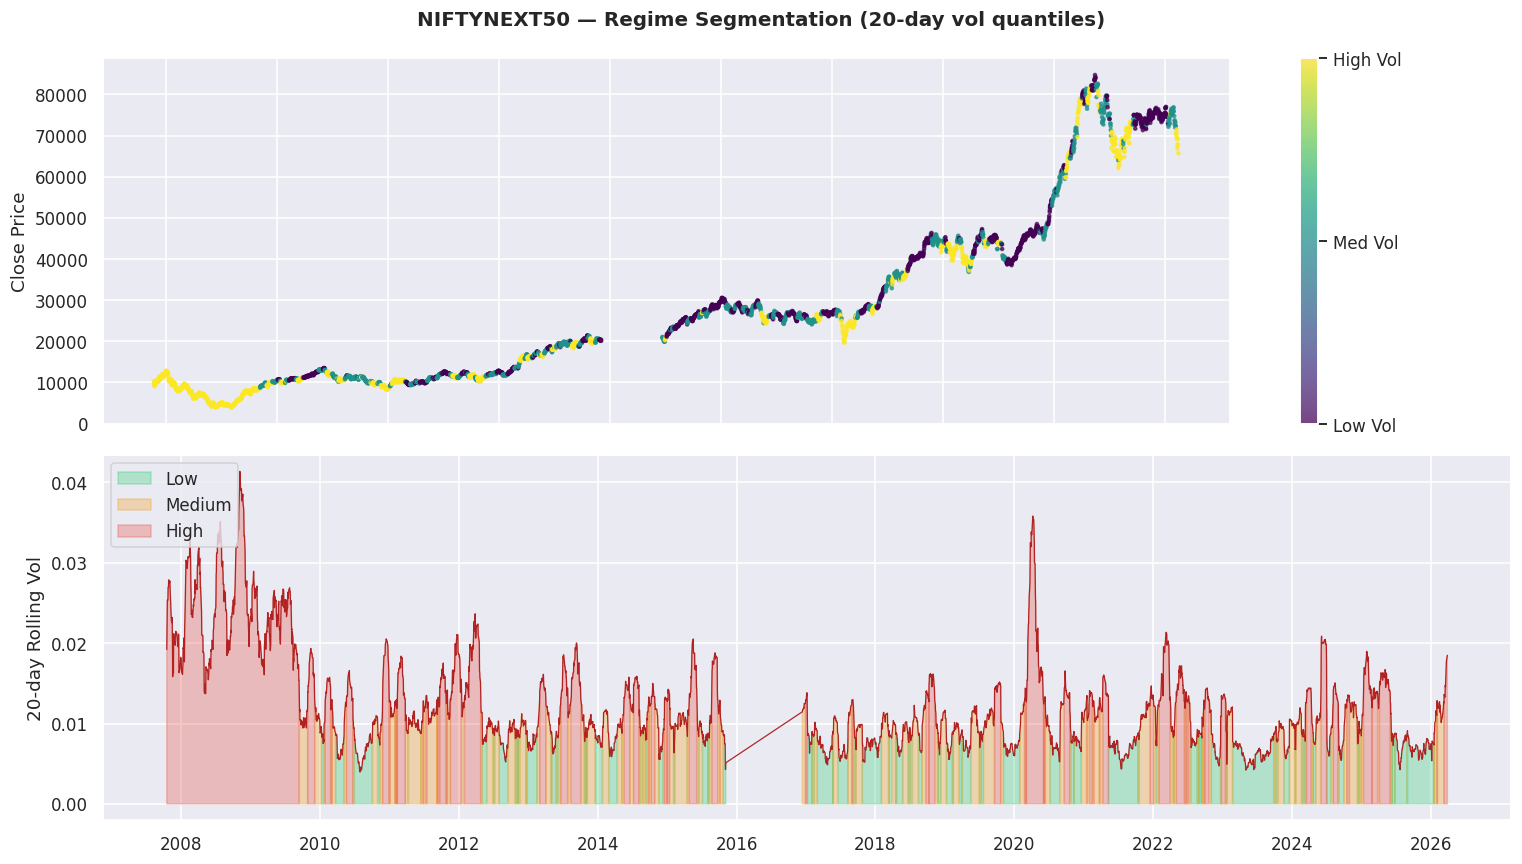

  Saved: /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot04_NIFTYNEXT50_regime_segmentation.png
  NIFTYNEXT50 | Low    regime: 1428 days (33.3%)
  NIFTYNEXT50 | Medium regime: 1427 days (33.3%)
  NIFTYNEXT50 | High   regime: 1428 days (33.3%)


In [ ]:
for sym in SYMBOLS:
    if sym not in daily: continue
    df = daily[sym].copy()
    lr = np.log(df['close'] / df['close'].shift(1))
    df['volatility'] = lr.rolling(20).std()
    df = df.dropna(subset=['volatility'])

    df['vol_regime'] = pd.qcut(df['volatility'], q=3, labels=['Low','Medium','High'])
    colour_map = {'Low': 0, 'Medium': 1, 'High': 2}
    colours = df['vol_regime'].map(colour_map)

    fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
    fig.suptitle(f'{sym} — Regime Segmentation (20-day vol quantiles)',
                 fontsize=13, fontweight='bold')

    sc = axes[0].scatter(df.index, df['close'], c=colours, cmap='viridis',
                         s=4, alpha=0.7)
    axes[0].set_ylabel('Close Price')
    cbar = fig.colorbar(sc, ax=axes[0], ticks=[0,1,2])
    cbar.set_ticklabels(['Low Vol','Med Vol','High Vol'])

    axes[1].plot(df.index, df['volatility'], color='firebrick', lw=0.8)
    for regime, col in [('Low','#2ecc71'),('Medium','#f39c12'),('High','#e74c3c')]:
        mask = df['vol_regime'] == regime
        axes[1].fill_between(df.index, 0, df['volatility'],
                             where=mask, alpha=0.3, color=col, label=regime)
    axes[1].set_ylabel('20-day Rolling Vol')
    axes[1].legend(loc='upper left')
    axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

    plt.tight_layout()
    savefig(f'Plot04_{sym}_regime_segmentation.png')

    # Regime duration stats
    for r in ['Low','Medium','High']:
        cnt = (df['vol_regime'] == r).sum()
        pct = cnt / len(df) * 100
        print(f'  {sym} | {r:6s} regime: {cnt:4d} days ({pct:.1f}%)')


## 2.11 — Intraday → Daily Lead-Lag
**Question:** Does intraday volatility lead daily volatility?

Uses 5-min bars to compute daily intraday realised vol, then cross-correlates
with next-day daily vol. A positive lagged correlation is a key paper contribution.


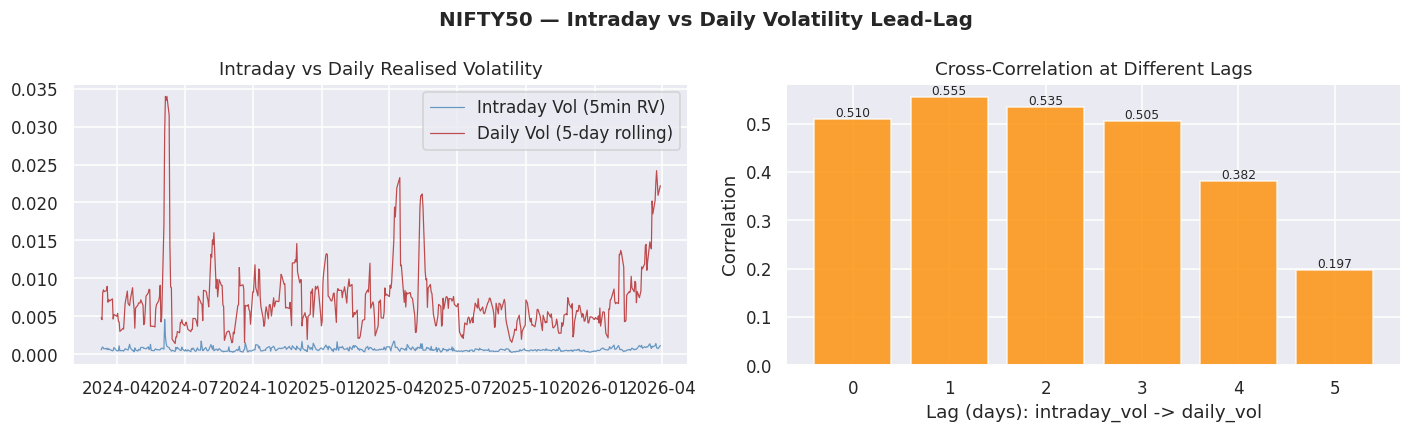

  Saved: /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot05_NIFTY50_intraday_daily_lead_lag.png
  NIFTY50: lag-1 corr = 0.5555 (intraday vol -> next-day vol)


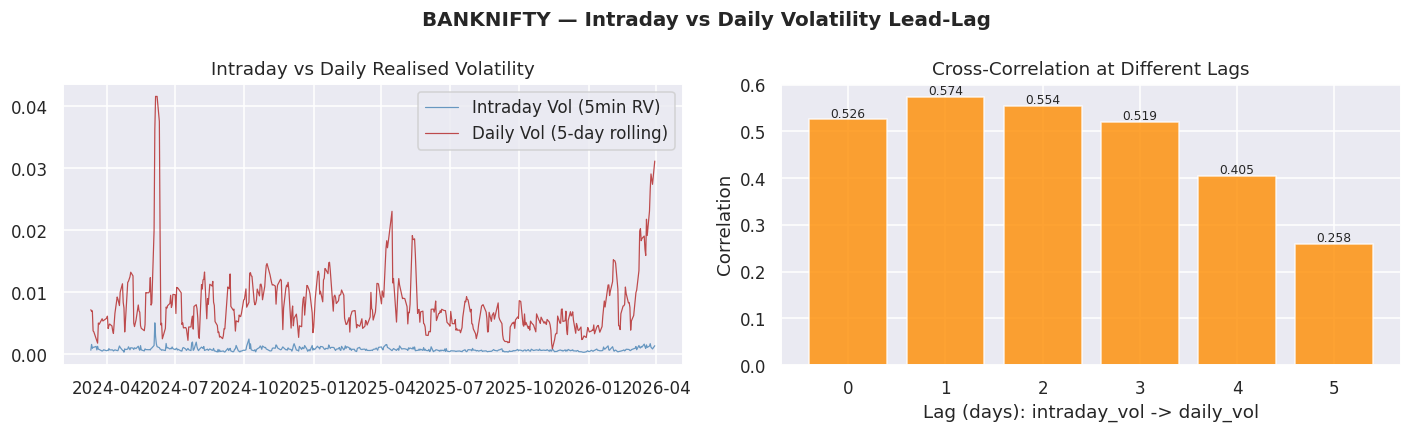

  Saved: /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot05_BANKNIFTY_intraday_daily_lead_lag.png
  BANKNIFTY: lag-1 corr = 0.5736 (intraday vol -> next-day vol)


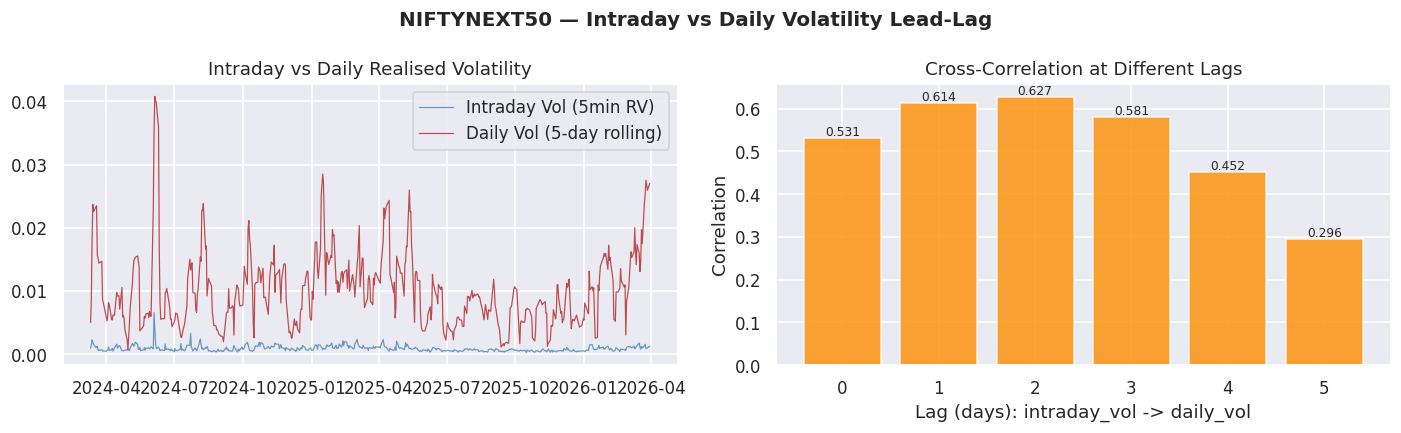

  Saved: /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot05_NIFTYNEXT50_intraday_daily_lead_lag.png
  NIFTYNEXT50: lag-1 corr = 0.6136 (intraday vol -> next-day vol)


In [ ]:
lead_lag_results = []

for sym in SYMBOLS:
    if sym not in resampled or '5min' not in resampled[sym]: continue
    if sym not in daily: continue

    # Daily realised vol from same-session 5-min returns.
    df5 = resampled[sym]['5min'].copy()
    df5['session'] = df5.index.normalize()
    df5['lr'] = df5.groupby('session')['close'].transform(lambda s: np.log(s / s.shift(1)))
    intraday_rv = df5.groupby('session')['lr'].std().dropna()
    intraday_rv.name = 'intraday_vol'

    # Daily vol from daily close
    lr_d = np.log(daily[sym]['close'] / daily[sym]['close'].shift(1))
    daily_rv = lr_d.rolling(5).std().dropna()
    daily_rv.name = 'daily_vol'

    merged = pd.concat([intraday_rv, daily_rv], axis=1).dropna()
    if len(merged) < 30: continue

    # Cross-correlation at lags 0..5
    lags = range(0, 6)
    corrs = [merged['intraday_vol'].shift(lag).corr(merged['daily_vol']) for lag in lags]

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    fig.suptitle(f'{sym} — Intraday vs Daily Volatility Lead-Lag',
                 fontsize=13, fontweight='bold')

    axes[0].plot(merged.index, merged['intraday_vol'], label='Intraday Vol (5min RV)',
                 color='steelblue', lw=0.8, alpha=0.8)
    axes[0].plot(merged.index, merged['daily_vol'], label='Daily Vol (5-day rolling)',
                 color='firebrick', lw=0.8, alpha=0.8)
    axes[0].set_title('Intraday vs Daily Realised Volatility')
    axes[0].legend()

    axes[1].bar(list(lags), corrs, color='darkorange', alpha=0.8)
    axes[1].axhline(0, color='k', lw=0.8)
    axes[1].set_xlabel('Lag (days): intraday_vol -> daily_vol')
    axes[1].set_ylabel('Correlation')
    axes[1].set_title('Cross-Correlation at Different Lags')
    for i, c in enumerate(corrs):
        axes[1].text(i, c + 0.005, f'{c:.3f}', ha='center', fontsize=8)

    plt.tight_layout()
    savefig(f'Plot05_{sym}_intraday_daily_lead_lag.png')

    lead_lag_results.append({'symbol': sym, **{f'lag{l}_corr': round(c,4)
                                                for l, c in zip(lags, corrs)}})
    print(f'  {sym}: lag-1 corr = {corrs[1]:.4f} (intraday vol -> next-day vol)')

if lead_lag_results:
    pd.DataFrame(lead_lag_results).to_csv(
        os.path.join(RESULTS_DIR, 'lead_lag_correlations.csv'), index=False)


## 2.12 — Extreme Event Analysis
**Question:** What happens during crashes? Are extreme returns clustered?

Events beyond the 99th percentile in absolute return. Clustering confirms
regime persistence and motivates crisis-detection features.


  NIFTY50: 23 extremes | 23 occur in top-quartile vol periods
  BANKNIFTY: 26 extremes | 23 occur in top-quartile vol periods
  NIFTYNEXT50: 30 extremes | 22 occur in top-quartile vol periods


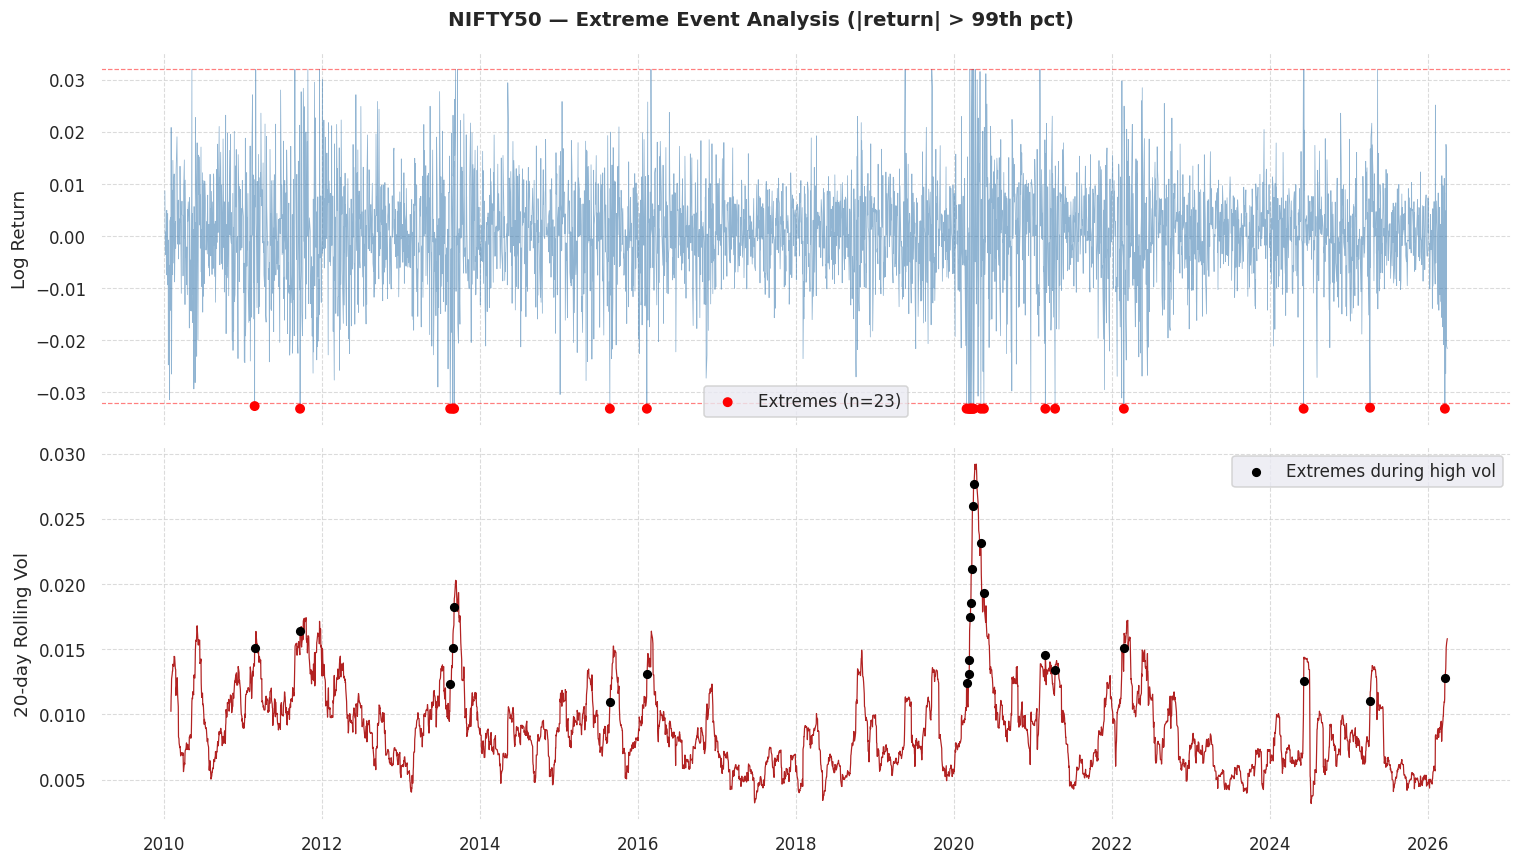

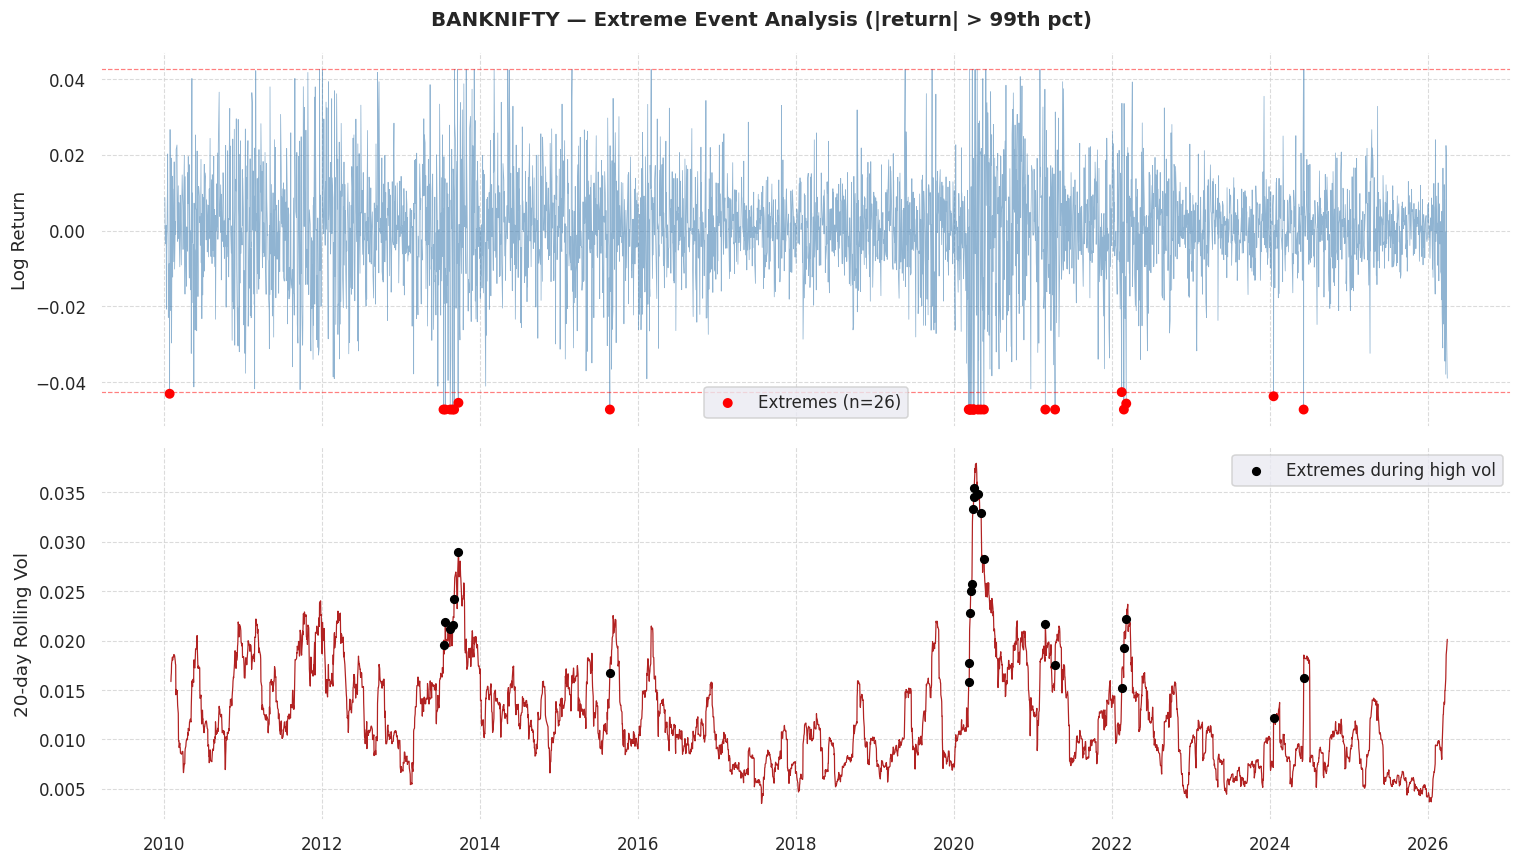

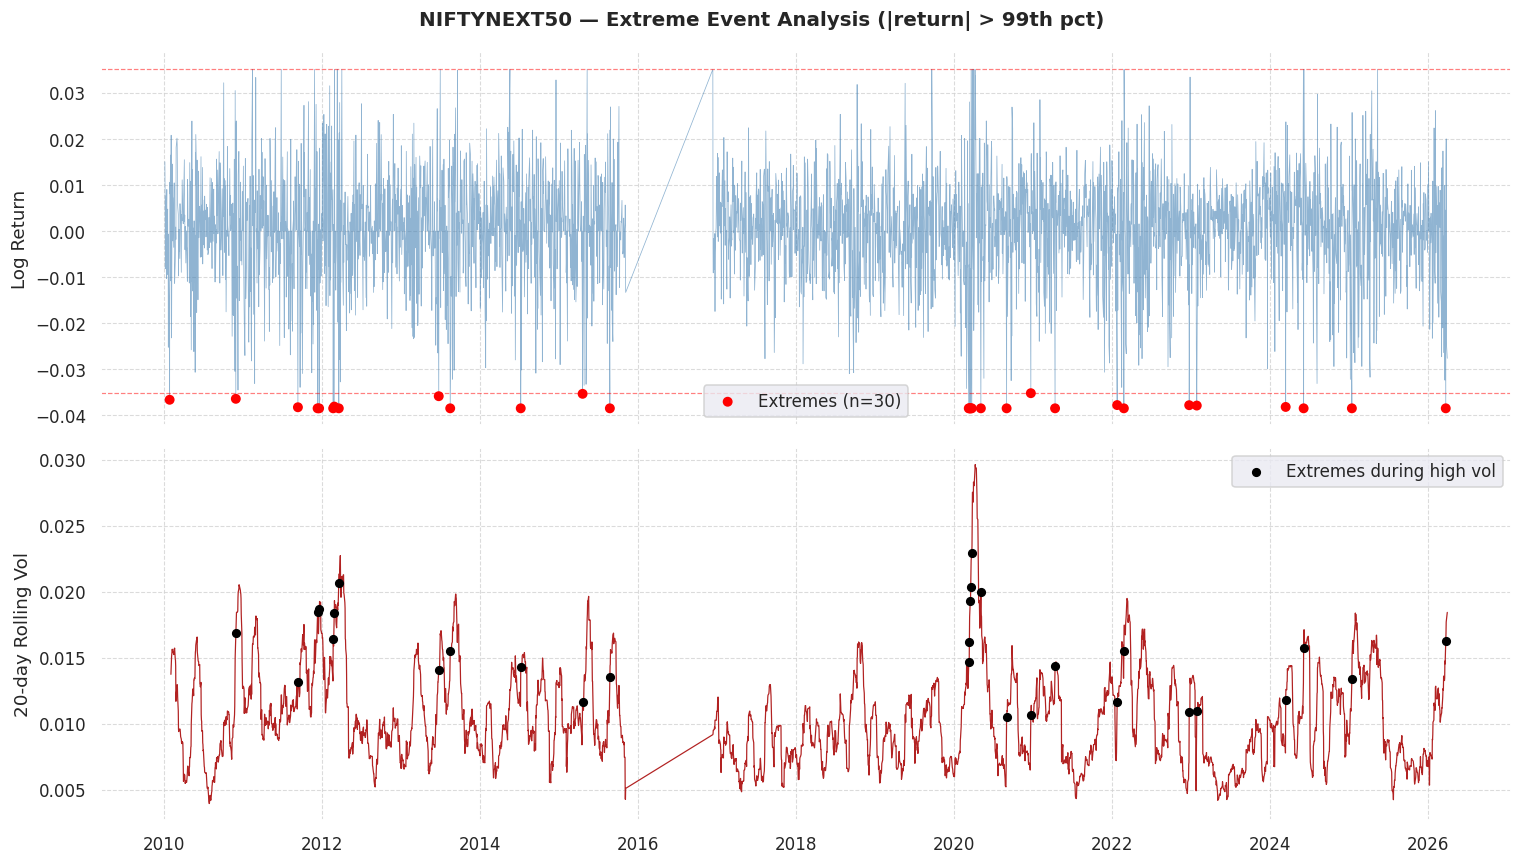

In [26]:
for sym in SYMBOLS:
    if sym not in daily: continue
    lr = np.log(daily[sym]['close'] / daily[sym]['close'].shift(1)).dropna()
    threshold  = lr.abs().quantile(0.99)
    extremes   = lr[lr.abs() > threshold]
    roll_vol   = lr.rolling(20).std()

    fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
    fig.suptitle(f'{sym} — Extreme Event Analysis (|return| > 99th pct)', fontsize=13, fontweight='bold')

    for ax in axes:
        ax.set_facecolor('white')
        ax.grid(True, axis='both', color='lightgray', linestyle='--', linewidth=0.7, alpha=0.8, zorder=0)
        ax.set_axisbelow(True)

    axes[0].plot(lr.index, lr.values, color='steelblue', lw=0.5, alpha=0.6)
    axes[0].scatter(extremes.index, extremes.values,
                    c=['red' if v < 0 else 'green' for v in extremes.values],
                    s=30, zorder=5, label=f'Extremes (n={len(extremes)})')
    axes[0].axhline(threshold, color='red', lw=0.8, ls='--', alpha=0.5)
    axes[0].axhline(-threshold, color='red', lw=0.8, ls='--', alpha=0.5)
    axes[0].set_ylabel('Log Return')
    axes[0].legend()

    axes[1].plot(roll_vol.index, roll_vol.values, color='firebrick', lw=0.8)
    axes[1].scatter(extremes.index, roll_vol.reindex(extremes.index),
                    color='black', s=25, zorder=5, label='Extremes during high vol')
    axes[1].set_ylabel('20-day Rolling Vol')
    axes[1].legend()
    axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

    fig.patch.set_facecolor('white')
    plt.tight_layout()
    # savefig(f'Plot06_{sym}_extreme_events.png')

    in_high_vol = (roll_vol.reindex(extremes.index) >
                   roll_vol.quantile(0.75)).sum()
    print(f'  {sym}: {len(extremes)} extremes | {in_high_vol} occur in top-quartile vol periods')


## 2.13 — Volume–Volatility Relationship
**Question:** Does volume confirm volatility spikes?

Volume spike = regime shift signal. Useful feature for Phase 03.


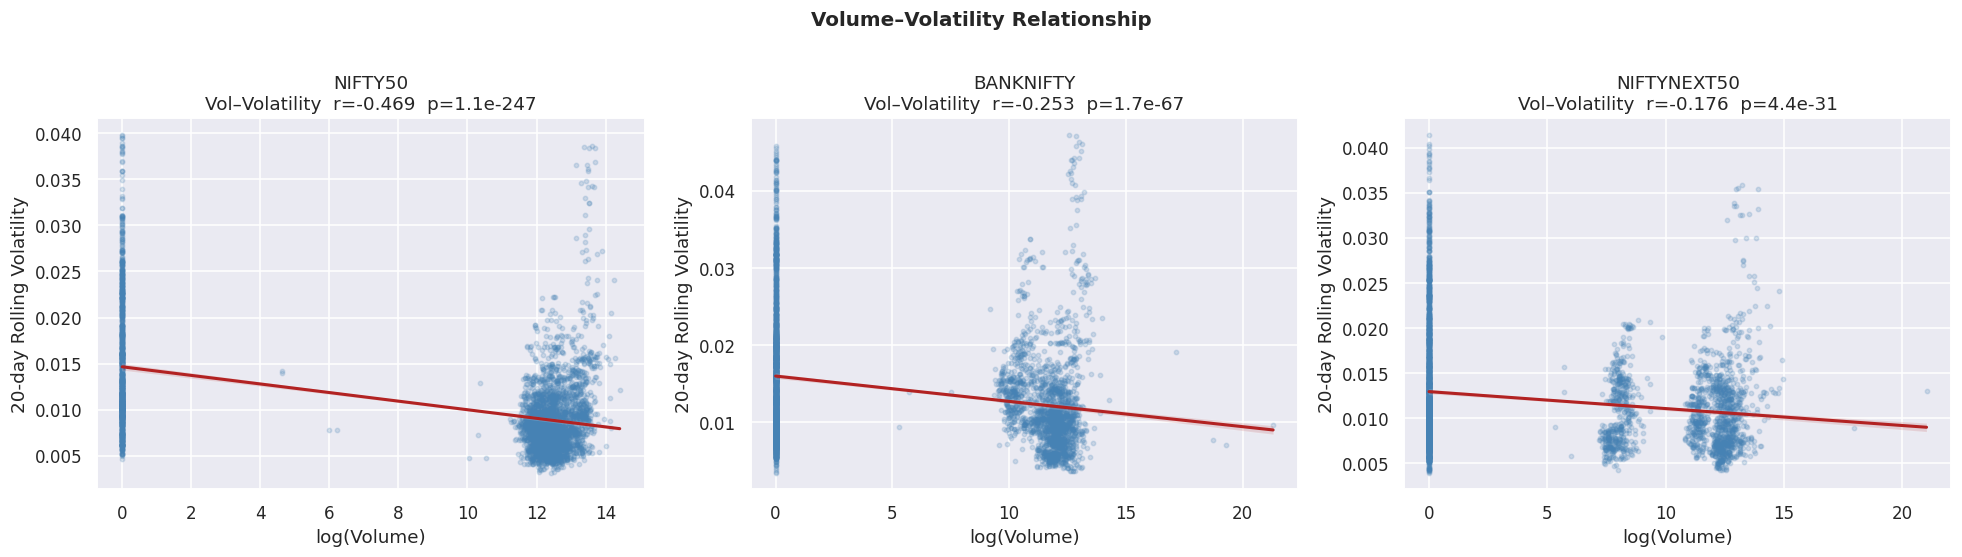

  Saved: /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot07_all_symbols_volume_volatility.png


In [ ]:
fig, axes = plt.subplots(1, len(SYMBOLS), figsize=(6*len(SYMBOLS), 5))
if len(SYMBOLS) == 1: axes = [axes]

for ax, sym in zip(axes, SYMBOLS):
    if sym not in daily: continue
    df = daily[sym].copy()
    lr = np.log(df['close'] / df['close'].shift(1))
    df['volatility'] = lr.rolling(20).std()
    df['log_volume'] = np.log1p(df['volume'])
    df = df.dropna(subset=['volatility'])

    sns.regplot(x='log_volume', y='volatility', data=df, ax=ax,
                scatter_kws={'alpha': 0.2, 's': 8, 'color': 'steelblue'},
                line_kws={'color': 'firebrick', 'lw': 2})

    r, p = stats.pearsonr(df['log_volume'].dropna(), df['volatility'].dropna()
                          .reindex(df['log_volume'].dropna().index).dropna())
    ax.set_title(f'{sym}\nVol–Volatility  r={r:.3f}  p={p:.1e}')
    ax.set_xlabel('log(Volume)')
    ax.set_ylabel('20-day Rolling Volatility')

plt.suptitle('Volume–Volatility Relationship', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
savefig('Plot07_all_symbols_volume_volatility.png')


## 2.14 — Intraday Volatility by Hour
**Question:** When does volatility occur during the trading day?

Uses 5-min bars. Opening (09:15–10:15) and closing (14:30–15:30) typically
show highest volatility — confirms features like 'opening vol' and 'closing vol'.


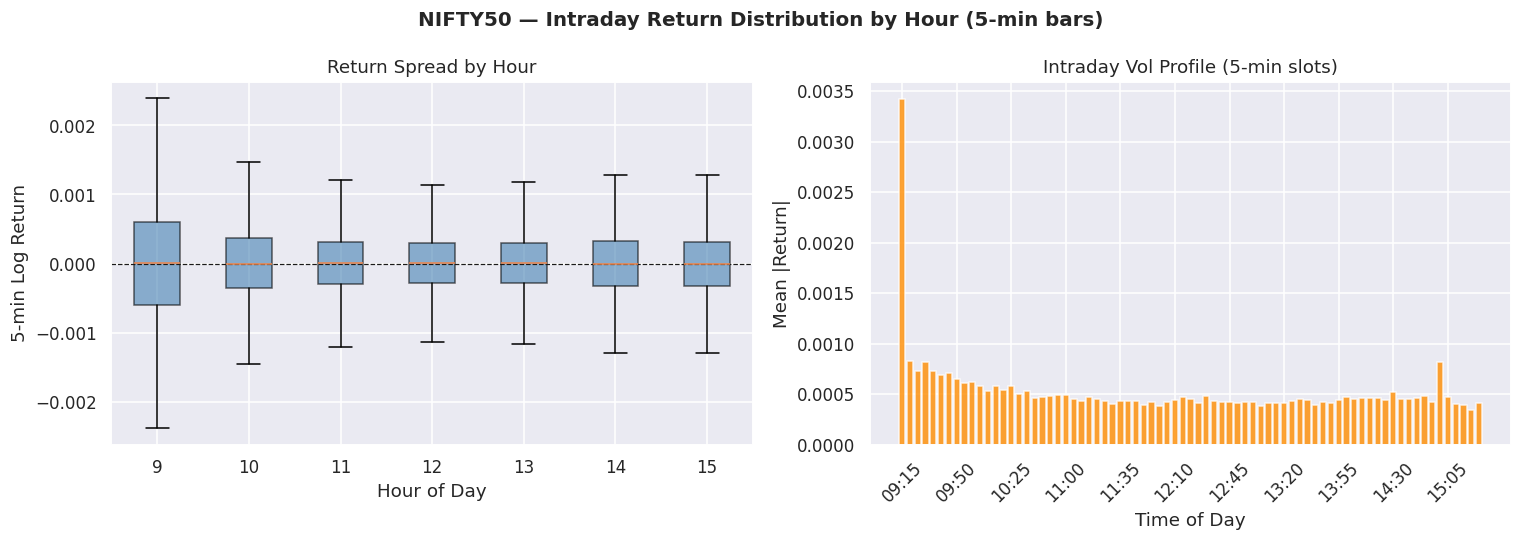

  Saved: /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot08_NIFTY50_intraday_vol_by_hour.png
  NIFTY50: peak vol at 09:15


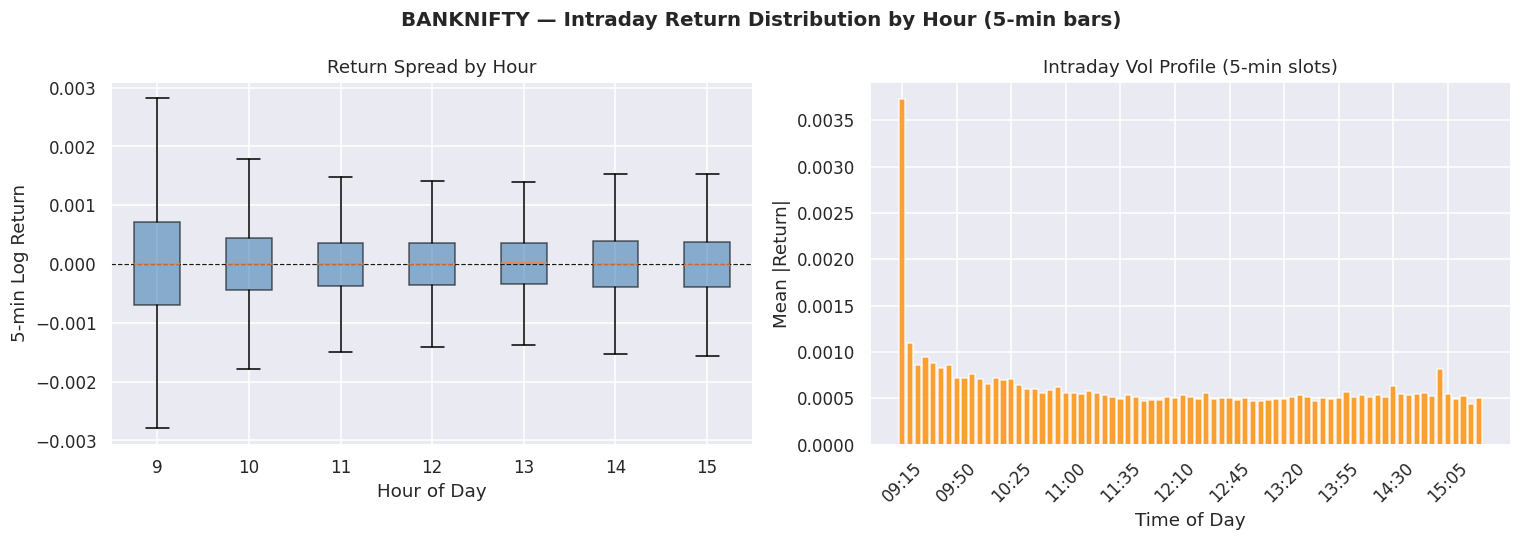

  Saved: /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot08_BANKNIFTY_intraday_vol_by_hour.png
  BANKNIFTY: peak vol at 09:15


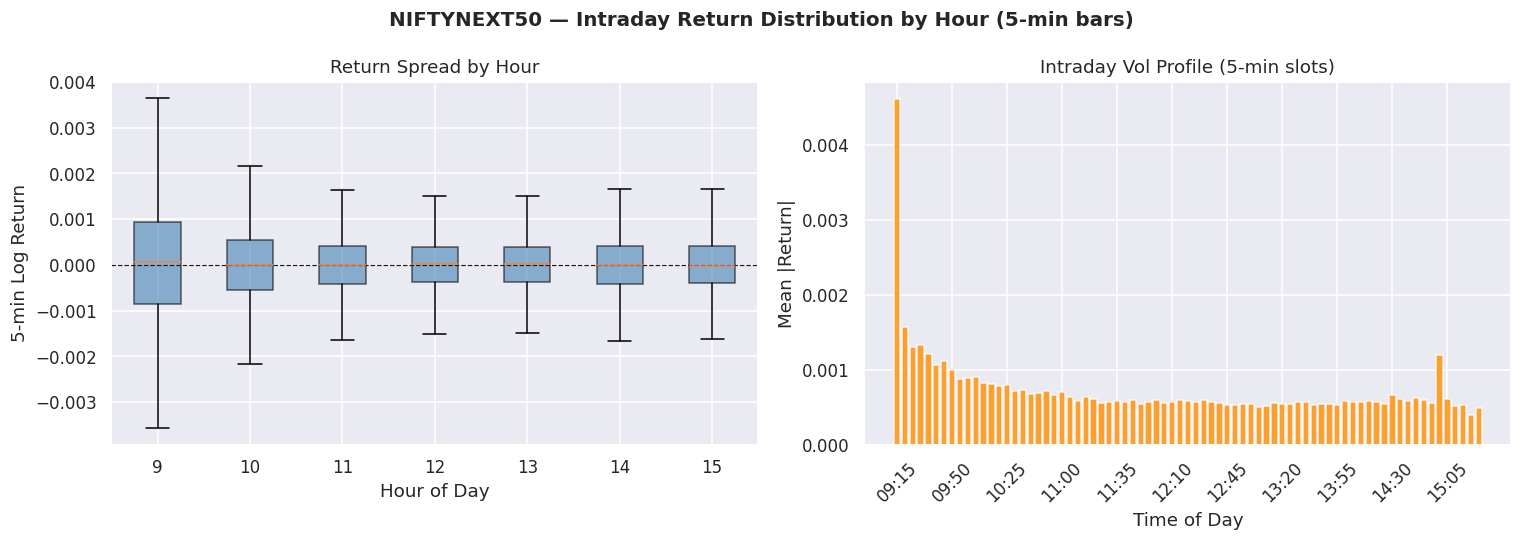

  Saved: /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot08_NIFTYNEXT50_intraday_vol_by_hour.png
  NIFTYNEXT50: peak vol at 09:15


In [ ]:
for sym in SYMBOLS:
    if sym not in resampled: continue
    # Use 5-min for intraday hour analysis
    df5 = resampled[sym].get('5min', pd.DataFrame())
    if df5.empty: continue

    df5 = df5.copy()
    df5['returns'] = np.log(df5['close'] / df5['close'].shift(1))
    df5['hour']    = df5.index.hour
    df5['minute']  = df5.index.minute
    df5['hhmm']    = df5['hour'] * 100 + df5['minute']
    df5 = df5.dropna(subset=['returns'])

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle(f'{sym} — Intraday Return Distribution by Hour (5-min bars)',
                 fontsize=13, fontweight='bold')

    # Boxplot by hour
    hour_groups = [df5[df5['hour'] == h]['returns'].values
                   for h in sorted(df5['hour'].unique())]
    hour_labels = sorted(df5['hour'].unique())
    bp = axes[0].boxplot(hour_groups, labels=hour_labels,
                         patch_artist=True, showfliers=False)
    for patch in bp['boxes']:
        patch.set_facecolor('steelblue')
        patch.set_alpha(0.6)
    axes[0].set_xlabel('Hour of Day')
    axes[0].set_ylabel('5-min Log Return')
    axes[0].set_title('Return Spread by Hour')
    axes[0].axhline(0, color='k', lw=0.8, ls='--')

    # Mean absolute return (= intraday vol proxy) by 5-min slot
    abs_ret_by_slot = df5.groupby('hhmm')['returns'].apply(lambda x: x.abs().mean())
    axes[1].bar(range(len(abs_ret_by_slot)), abs_ret_by_slot.values,
                color='darkorange', alpha=0.8)
    tick_step = max(1, len(abs_ret_by_slot)//10)
    axes[1].set_xticks(range(0, len(abs_ret_by_slot), tick_step))
    axes[1].set_xticklabels(
        [f"{h//100:02d}:{h%100:02d}" for h in
         abs_ret_by_slot.index[::tick_step]], rotation=45)
    axes[1].set_xlabel('Time of Day')
    axes[1].set_ylabel('Mean |Return|')
    axes[1].set_title('Intraday Vol Profile (5-min slots)')

    plt.tight_layout()
    savefig(f'Plot08_{sym}_intraday_vol_by_hour.png')

    # Identify peak vol slot
    peak_slot = abs_ret_by_slot.idxmax()
    print(f'  {sym}: peak vol at {peak_slot//100:02d}:{peak_slot%100:02d}')


## 2.15 — Cross-Market Spread (BANKNIFTY − NIFTY50)
**Question:** Do indices diverge under stress?

Relative return spread spikes during crisis — useful as a regime indicator feature.


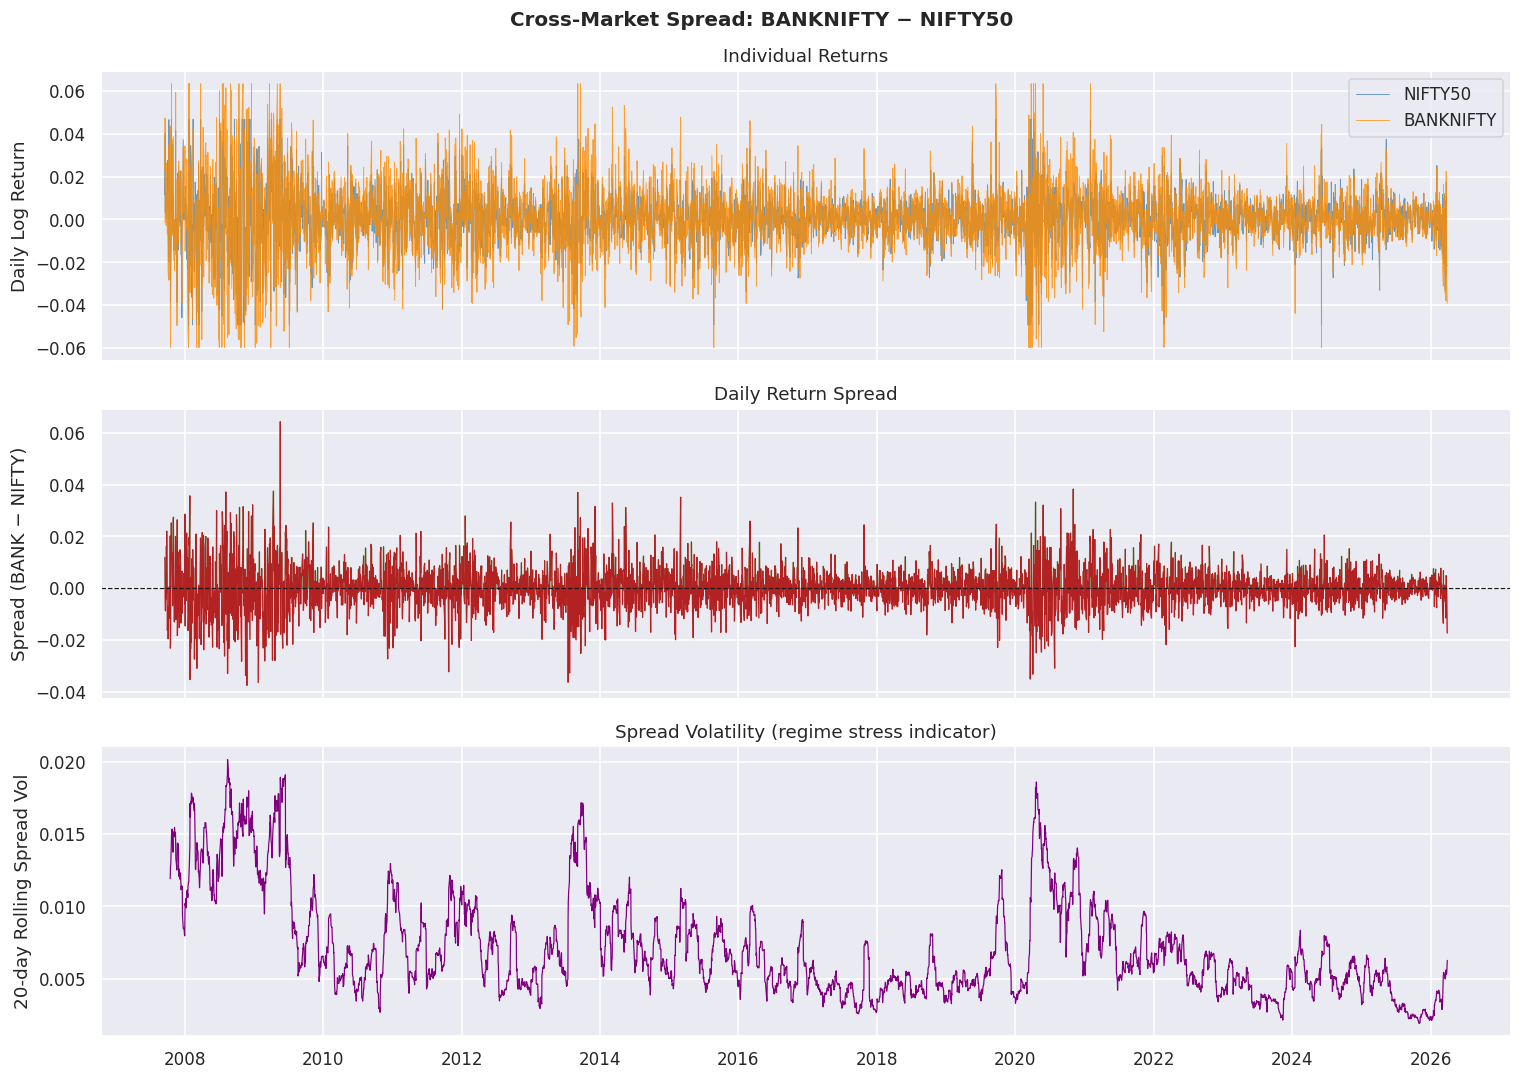

  Saved: /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot09_cross_market_spread_BANK_vs_NIFTY.png
  Spread stats: {'mean': np.float64(0.0001), 'std': 0.00802, 'skew': 0.245, 'kurt': 3.4041}


In [ ]:
if 'NIFTY50' in daily and 'BANKNIFTY' in daily:
    # Align on common dates
    ret_n  = np.log(daily['NIFTY50']['close'] / daily['NIFTY50']['close'].shift(1))
    ret_b  = np.log(daily['BANKNIFTY']['close'] / daily['BANKNIFTY']['close'].shift(1))
    spread = (ret_b - ret_n).dropna()
    roll_spread_vol = spread.rolling(20).std()

    fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
    fig.suptitle('Cross-Market Spread: BANKNIFTY − NIFTY50',
                 fontsize=13, fontweight='bold')

    axes[0].plot(ret_n.index, ret_n.values, label='NIFTY50',
                 color='steelblue', lw=0.6, alpha=0.8)
    axes[0].plot(ret_b.index, ret_b.values, label='BANKNIFTY',
                 color='darkorange', lw=0.6, alpha=0.8)
    axes[0].set_ylabel('Daily Log Return')
    axes[0].legend()
    axes[0].set_title('Individual Returns')

    axes[1].plot(spread.index, spread.values, color='firebrick', lw=0.7)
    axes[1].axhline(spread.mean(), color='k', ls='--', lw=0.8)
    axes[1].fill_between(spread.index, spread, 0,
                         where=(spread > 0), alpha=0.3, color='green')
    axes[1].fill_between(spread.index, spread, 0,
                         where=(spread < 0), alpha=0.3, color='red')
    axes[1].set_ylabel('Spread (BANK − NIFTY)')
    axes[1].set_title('Daily Return Spread')

    axes[2].plot(roll_spread_vol.index, roll_spread_vol.values,
                 color='purple', lw=0.8)
    axes[2].set_ylabel('20-day Rolling Spread Vol')
    axes[2].set_title('Spread Volatility (regime stress indicator)')
    axes[2].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

    plt.tight_layout()
    savefig('Plot09_cross_market_spread_BANK_vs_NIFTY.png')

    spread_stats = {
        'mean': round(spread.mean(), 5), 'std': round(spread.std(), 5),
        'skew': round(float(stats.skew(spread)), 4),
        'kurt': round(float(stats.kurtosis(spread)), 4),
    }
    print('  Spread stats:', spread_stats)
    pd.DataFrame([spread_stats]).to_csv(
        os.path.join(RESULTS_DIR, 'cross_market_spread_stats.csv'), index=False)
else:
    print('  SKIP: need both NIFTY50 and BANKNIFTY')


## 2.16 — Regime Transition Detection
**Question:** How do regimes change?

Volatility acceleration (first difference of rolling vol) reveals sudden regime shifts.
Large spikes in `vol_diff` are candidate change-points.


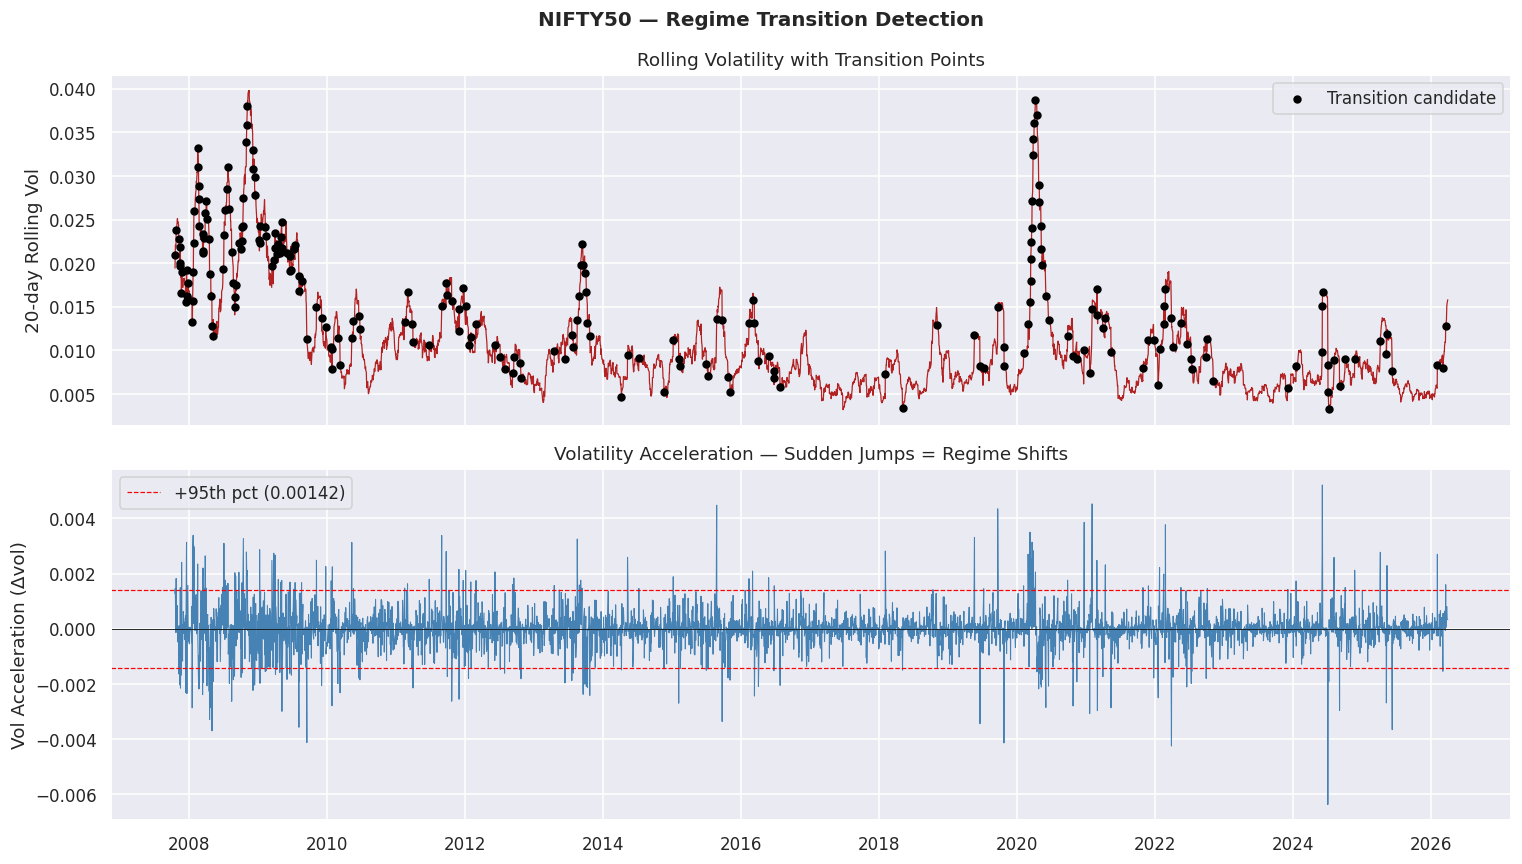

  Saved: /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot10_NIFTY50_regime_transitions.png
  NIFTY50: 228 regime transition candidates detected


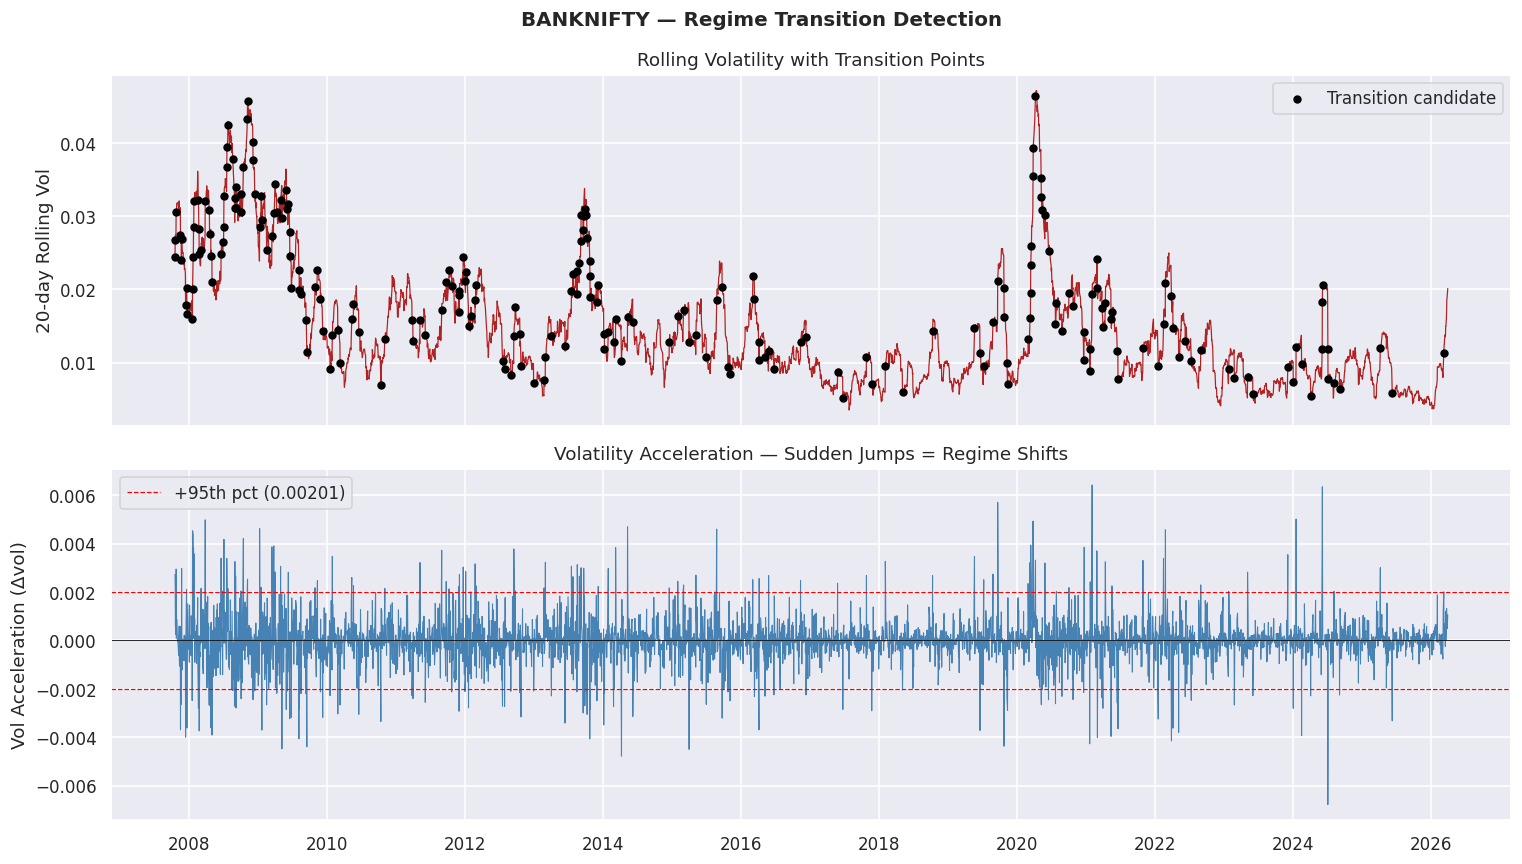

  Saved: /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot10_BANKNIFTY_regime_transitions.png
  BANKNIFTY: 228 regime transition candidates detected


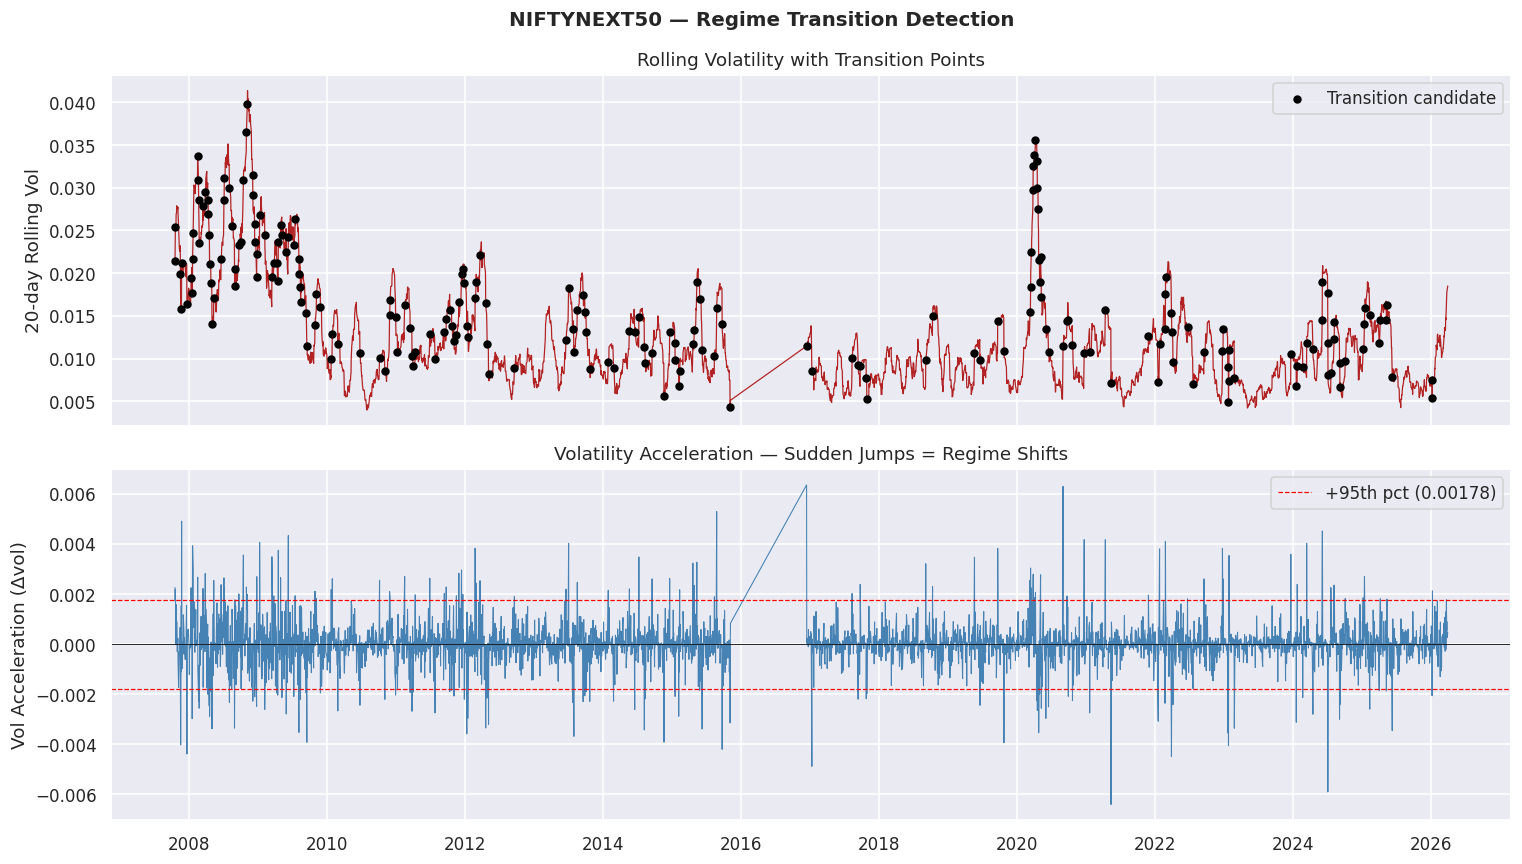

  Saved: /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot10_NIFTYNEXT50_regime_transitions.png
  NIFTYNEXT50: 215 regime transition candidates detected


In [ ]:
for sym in SYMBOLS:
    if sym not in daily: continue
    df = daily[sym].copy()
    lr = np.log(df['close'] / df['close'].shift(1))
    df['vol']      = lr.rolling(20).std()
    df['vol_diff'] = df['vol'].diff()
    df = df.dropna(subset=['vol_diff'])

    # Flag top-5% acceleration as transition candidates
    threshold = df['vol_diff'].abs().quantile(0.95)
    transitions = df[df['vol_diff'].abs() > threshold]

    fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
    fig.suptitle(f'{sym} — Regime Transition Detection',
                 fontsize=13, fontweight='bold')

    axes[0].plot(df.index, df['vol'], color='firebrick', lw=0.8)
    axes[0].scatter(transitions.index, transitions['vol'],
                    color='black', s=20, zorder=5, label='Transition candidate')
    axes[0].set_ylabel('20-day Rolling Vol')
    axes[0].set_title('Rolling Volatility with Transition Points')
    axes[0].legend()

    axes[1].plot(df.index, df['vol_diff'], color='steelblue', lw=0.7)
    axes[1].axhline(threshold, color='red', ls='--', lw=0.8, label=f'+95th pct ({threshold:.5f})')
    axes[1].axhline(-threshold, color='red', ls='--', lw=0.8)
    axes[1].axhline(0, color='k', lw=0.6)
    axes[1].set_ylabel('Vol Acceleration (Δvol)')
    axes[1].set_title('Volatility Acceleration — Sudden Jumps = Regime Shifts')
    axes[1].legend()
    axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

    plt.tight_layout()
    savefig(f'Plot10_{sym}_regime_transitions.png')
    print(f'  {sym}: {len(transitions)} regime transition candidates detected')


## 2.17 — Rolling Correlation (Time-Varying)
**Question:** Is the NIFTY50–BANKNIFTY correlation stable over time?

Correlation rises during crisis — markets become more co-integrated under stress.
Also plots NIFTY50–NIFTYNEXT50 rolling correlation.


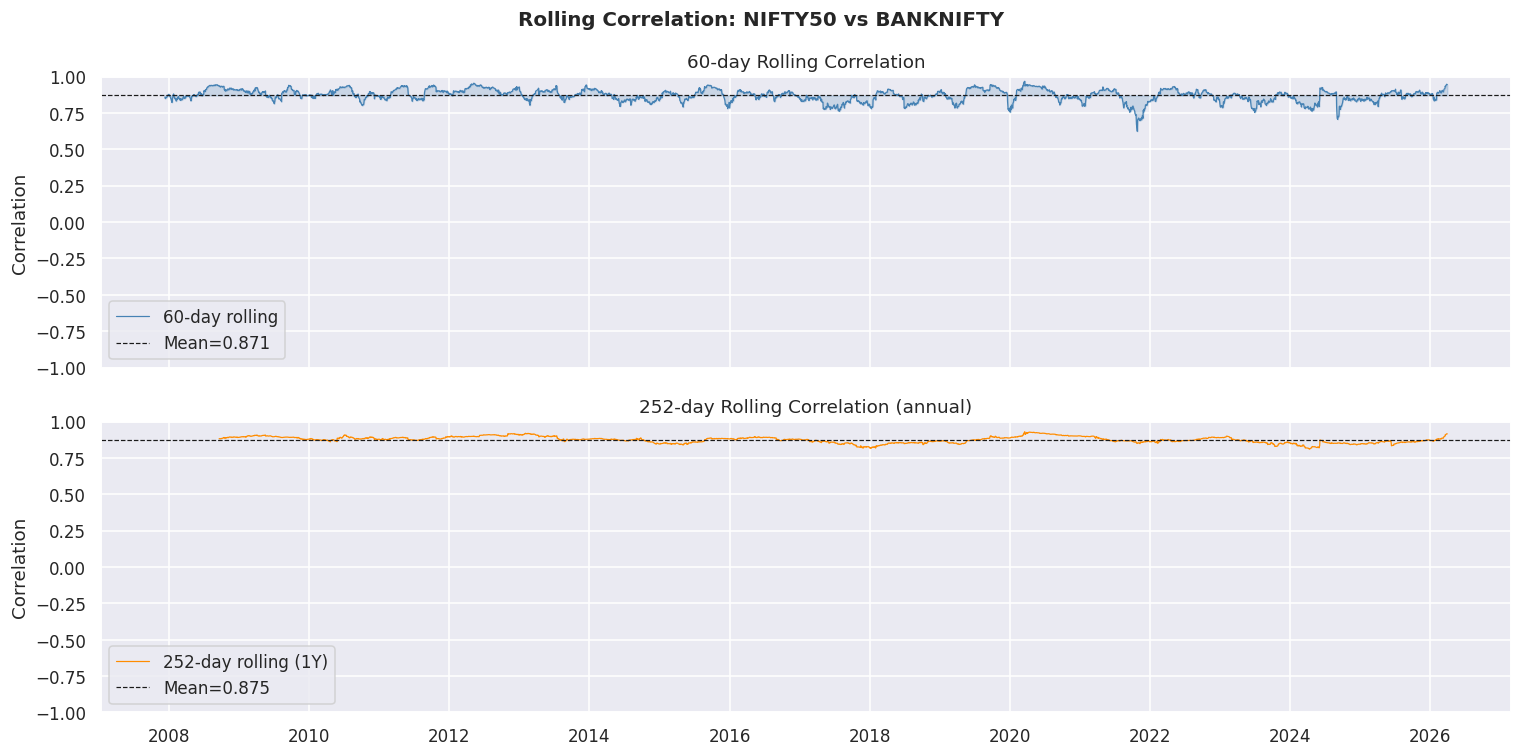

  Saved: /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot11_rolling_corr_NIFTY50_vs_BANKNIFTY.png
  NIFTY50 vs BANKNIFTY: static=0.8809 | stress=0.9337


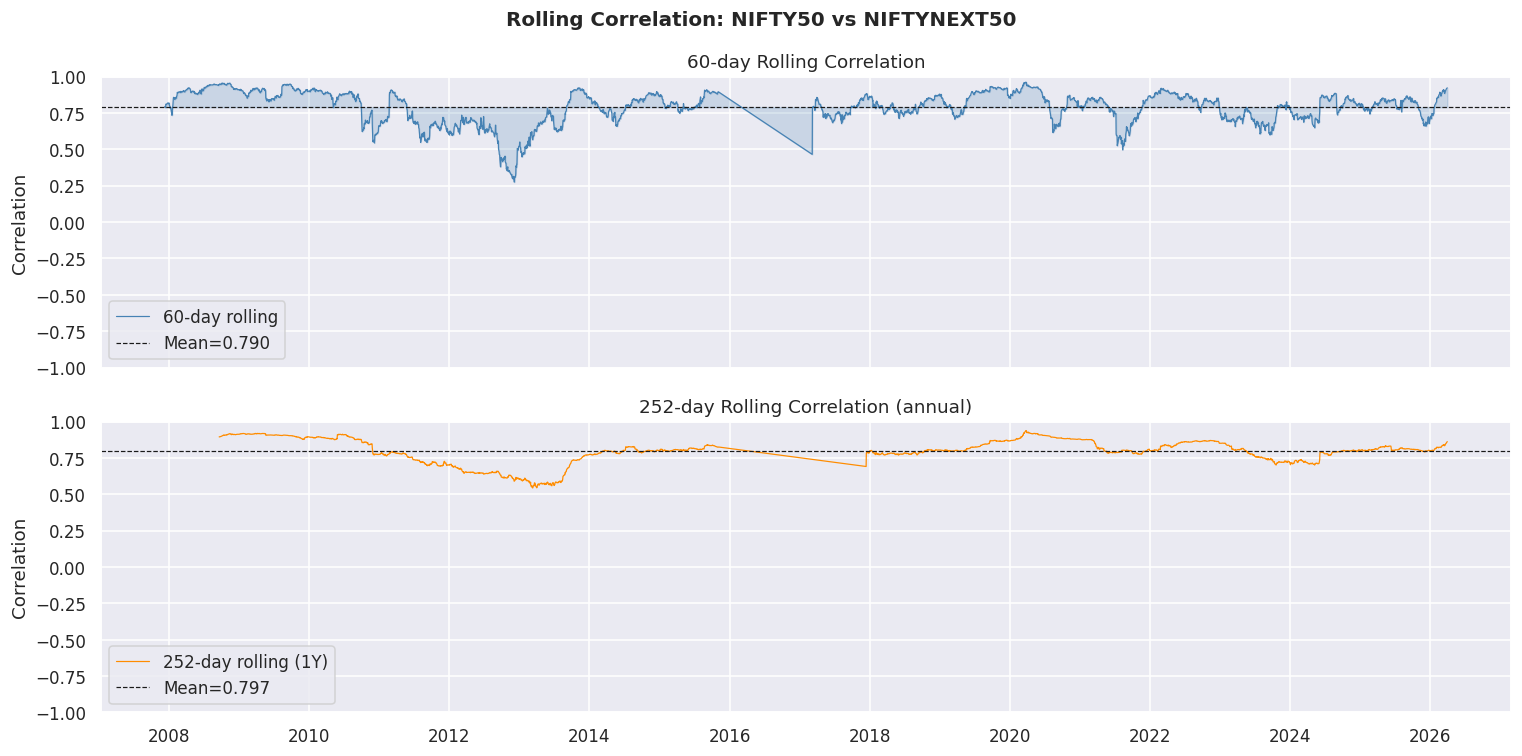

  Saved: /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot11_rolling_corr_NIFTY50_vs_NIFTYNEXT50.png
  NIFTY50 vs NIFTYNEXT50: static=0.8283 | stress=0.9270


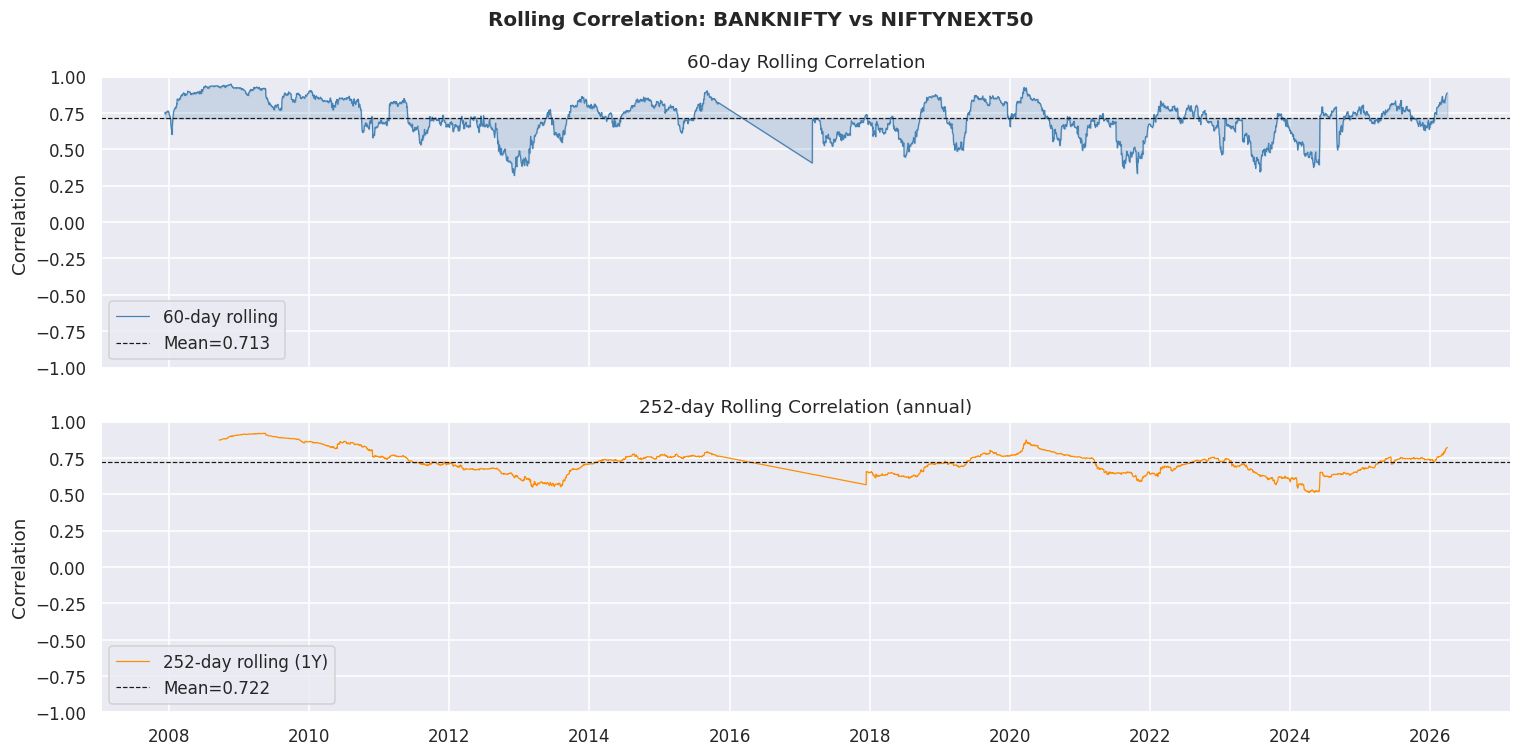

  Saved: /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Output/EDA_Plots/Plot11_rolling_corr_BANKNIFTY_vs_NIFTYNEXT50.png
  BANKNIFTY vs NIFTYNEXT50: static=0.7690 | stress=0.9034


In [ ]:
pairs = [
    ('NIFTY50', 'BANKNIFTY'),
    ('NIFTY50', 'NIFTYNEXT50'),
    ('BANKNIFTY', 'NIFTYNEXT50'),
]

corr_results = []

for sym_a, sym_b in pairs:
    if sym_a not in daily or sym_b not in daily: continue
    ret_a = np.log(daily[sym_a]['close'] / daily[sym_a]['close'].shift(1))
    ret_b = np.log(daily[sym_b]['close'] / daily[sym_b]['close'].shift(1))

    roll_corr_60  = ret_a.rolling(60).corr(ret_b).dropna()
    roll_corr_252 = ret_a.rolling(252).corr(ret_b).dropna()

    fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
    fig.suptitle(f'Rolling Correlation: {sym_a} vs {sym_b}',
                 fontsize=13, fontweight='bold')

    axes[0].plot(roll_corr_60.index, roll_corr_60.values,
                 color='steelblue', lw=0.8, label='60-day rolling')
    axes[0].axhline(roll_corr_60.mean(), color='k', ls='--', lw=0.8,
                    label=f'Mean={roll_corr_60.mean():.3f}')
    axes[0].set_ylim(-1, 1)
    axes[0].set_ylabel('Correlation')
    axes[0].set_title('60-day Rolling Correlation')
    axes[0].legend()
    axes[0].fill_between(roll_corr_60.index, roll_corr_60, roll_corr_60.mean(),
                         alpha=0.2, color='steelblue')

    axes[1].plot(roll_corr_252.index, roll_corr_252.values,
                 color='darkorange', lw=0.8, label='252-day rolling (1Y)')
    axes[1].axhline(roll_corr_252.mean(), color='k', ls='--', lw=0.8,
                    label=f'Mean={roll_corr_252.mean():.3f}')
    axes[1].set_ylim(-1, 1)
    axes[1].set_ylabel('Correlation')
    axes[1].set_title('252-day Rolling Correlation (annual)')
    axes[1].legend()
    axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

    plt.tight_layout()
    savefig(f'Plot11_rolling_corr_{sym_a}_vs_{sym_b}.png')

    # Stress periods: top-10% correlation vs full-period static
    static_corr = ret_a.corr(ret_b)
    stress_corr = roll_corr_60[roll_corr_60 > roll_corr_60.quantile(0.90)].mean()
    corr_results.append({'pair': f'{sym_a}_vs_{sym_b}',
                         'static_corr': round(static_corr, 4),
                         'stress_corr_top10pct': round(stress_corr, 4)})
    print(f'  {sym_a} vs {sym_b}: static={static_corr:.4f} | stress={stress_corr:.4f}')

pd.DataFrame(corr_results).to_csv(
    os.path.join(RESULTS_DIR, 'rolling_correlation_results.csv'), index=False)


## 2.18 — Add Returns, Targets & Time Splits


In [ ]:
def add_daily_targets(df):
    df = df.copy()
    df['log_return'] = np.log(df['close'] / df['close'].shift(1))
    df['target_reg'] = df['log_return'].shift(-1)
    df['target_cls'] = (df['target_reg'] > 0).astype('Int64')
    df.loc[df['target_reg'].isna(), 'target_cls'] = pd.NA
    return df


def add_intraday_targets(df):
    df = df.copy()
    session = df.index.normalize()
    df['log_return'] = df.groupby(session)['close'].transform(lambda s: np.log(s / s.shift(1)))
    df['target_reg'] = df.groupby(session)['log_return'].shift(-1)
    df['target_cls'] = (df['target_reg'] > 0).astype('Int64')
    df.loc[df['target_reg'].isna(), 'target_cls'] = pd.NA
    return df


def split_bounds(index, train_frac=TRAIN_FRAC, val_frac=VAL_FRAC):
    idx = pd.Index(index).sort_values().unique()
    n = len(idx)
    train_end = int(n * train_frac)
    val_end = int(n * (train_frac + val_frac))
    return {
        'n_rows': int(n),
        'train_start': str(idx[0]) if n else None,
        'train_end': str(idx[train_end - 1]) if train_end > 0 else None,
        'val_start': str(idx[train_end]) if train_end < n else None,
        'val_end': str(idx[val_end - 1]) if val_end > train_end else None,
        'test_start': str(idx[val_end]) if val_end < n else None,
        'test_end': str(idx[-1]) if n else None,
    }

split_metadata = {
    'train_frac': TRAIN_FRAC,
    'val_frac': VAL_FRAC,
    'test_frac': round(1 - TRAIN_FRAC - VAL_FRAC, 4),
    'symbols': {},
}

for sym in list(daily.keys()):
    daily[sym] = add_daily_targets(daily[sym])
    split_metadata['symbols'].setdefault(sym, {})['1day'] = split_bounds(daily[sym].index)
    print(f'  {sym} daily targets added: {daily[sym]["target_reg"].notna().sum():,} rows')

for sym in list(resampled.keys()):
    split_metadata['symbols'].setdefault(sym, {})
    for tf, df in list(resampled[sym].items()):
        resampled[sym][tf] = add_intraday_targets(df)
        split_metadata['symbols'][sym][tf] = split_bounds(resampled[sym][tf].index)
        print(f'  {sym} {tf:5s} targets added: {resampled[sym][tf]["target_reg"].notna().sum():,} rows')

with open(os.path.join(RESULTS_DIR, 'split_metadata.json'), 'w') as f:
    json.dump(split_metadata, f, indent=2)

print('Target columns and split metadata saved.')


  NIFTY50 daily targets added: 4,570 rows
  BANKNIFTY daily targets added: 4,570 rows
  NIFTYNEXT50 daily targets added: 4,302 rows
  NIFTY50 5min  targets added: 36,809 rows
  NIFTY50 15min targets added: 11,937 rows
  NIFTY50 30min targets added: 5,969 rows
  NIFTY50 60min targets added: 2,985 rows
  BANKNIFTY 5min  targets added: 36,809 rows
  BANKNIFTY 15min targets added: 11,937 rows
  BANKNIFTY 30min targets added: 5,969 rows
  BANKNIFTY 60min targets added: 2,985 rows
  NIFTYNEXT50 5min  targets added: 36,809 rows
  NIFTYNEXT50 15min targets added: 11,937 rows
  NIFTYNEXT50 30min targets added: 5,969 rows
  NIFTYNEXT50 60min targets added: 2,985 rows
Target columns and split metadata saved.


## 2.19 — Save Cleaned CSVs to Drive


In [ ]:
save_log = []

# Daily
for sym in SYMBOLS:
    if sym not in daily or daily[sym].empty: continue
    path = os.path.join(CLEANED_DIR, f'{sym}_daily_cleaned.csv')
    daily[sym].to_csv(path)
    save_log.append({'symbol': sym, 'tf': '1day', 'rows': len(daily[sym])})
    print(f'  {sym} daily  : {len(daily[sym]):,} rows')

# 1-min
for sym in SYMBOLS:
    if sym not in min1 or min1[sym].empty: continue
    path = os.path.join(CLEANED_DIR, f'{sym}_1min_cleaned.csv')
    min1[sym].to_csv(path)
    save_log.append({'symbol': sym, 'tf': '1min', 'rows': len(min1[sym])})
    print(f'  {sym} 1min   : {len(min1[sym]):,} rows')

# Resampled
for sym in SYMBOLS:
    if sym not in resampled: continue
    for tf, df in resampled[sym].items():
        if df.empty: continue
        path = os.path.join(CLEANED_DIR, f'{sym}_{tf}_cleaned.csv')
        df.to_csv(path)
        save_log.append({'symbol': sym, 'tf': tf, 'rows': len(df)})
        print(f'  {sym} {tf:6s} : {len(df):,} rows')

pd.DataFrame(save_log).to_csv(os.path.join(RESULTS_DIR, 'phase02_save_log.csv'), index=False)
print('\nAll files saved. Phase 02 complete.')


  NIFTY50 daily  : 4,571 rows
  BANKNIFTY daily  : 4,571 rows
  NIFTYNEXT50 daily  : 4,303 rows
  NIFTY50 1min   : 186,534 rows
  BANKNIFTY 1min   : 186,533 rows
  NIFTYNEXT50 1min   : 186,534 rows
  NIFTY50 5min   : 37,308 rows
  NIFTY50 15min  : 12,436 rows
  NIFTY50 30min  : 6,468 rows
  NIFTY50 60min  : 3,484 rows
  BANKNIFTY 5min   : 37,308 rows
  BANKNIFTY 15min  : 12,436 rows
  BANKNIFTY 30min  : 6,468 rows
  BANKNIFTY 60min  : 3,484 rows
  NIFTYNEXT50 5min   : 37,308 rows
  NIFTYNEXT50 15min  : 12,436 rows
  NIFTYNEXT50 30min  : 6,468 rows
  NIFTYNEXT50 60min  : 3,484 rows

All files saved. Phase 02 complete.


## Phase 02 Complete

### CSVs saved to `Data/cleaned/`
| Pattern | Description |
|---------|-------------|
| `SYMBOL_daily_cleaned.csv` | Daily OHLCV + log_return + next-day target_reg + target_cls + volume_outlier |
| `SYMBOL_1min_cleaned.csv` | 1-min OHLCV (validated and session-filtered) |
| `SYMBOL_5min_cleaned.csv` | Resampled from 1-min + same-session log_return + next-bar targets |
| `SYMBOL_15min_cleaned.csv` | Resampled from 1-min + same-session log_return + next-bar targets |
| `SYMBOL_30min_cleaned.csv` | Resampled from 1-min + same-session log_return + next-bar targets |
| `SYMBOL_60min_cleaned.csv` | Resampled from 1-min + same-session log_return + next-bar targets |

### Plots saved to `Output/EDA_Plots/`
| Plot | Section |
|------|---------|
| `*_basic_eda.png` | 2.7 — log price, return hist, rolling vol, volume |
| `*_volatility_clustering.png` | 2.8 — ACF of rolling vol & squared returns |
| `all_symbols_qq_plot.png` | 2.9 — Q-Q plot vs Normal |
| `*_regime_segmentation.png` | 2.10 — colour-coded regimes on price |
| `*_intraday_daily_lead_lag.png` | 2.11 — cross-correlation at lags 0–5 |
| `*_extreme_events.png` | 2.12 — 99th-pct return spikes |
| `all_symbols_volume_volatility.png` | 2.13 — volume vs vol regression |
| `*_intraday_vol_by_hour.png` | 2.14 — return boxplot + vol profile by time |
| `cross_market_spread_BANK_vs_NIFTY.png` | 2.15 — spread + spread vol |
| `*_regime_transitions.png` | 2.16 — volatility acceleration change-points |
| `rolling_corr_*_vs_*.png` | 2.17 — 60-day & 252-day rolling correlation |

### Results saved to `Data/meta_results/`
`stationarity_report.csv` · `gap_report_daily.csv` · `split_metadata.json`
`lead_lag_correlations.csv` · `rolling_correlation_results.csv` · `cross_market_spread_stats.csv`

**Next:** `Phase03_Feature_Engineering.ipynb`
